# Instrução do Projeto

A Film Junky Union, uma nova comunidade para entusiastas de filmes clássicos, está desenvolvendo um sistema para filtrar e categorizar resenhas de filmes. O objetivo é treinar um modelo para detectar automaticamente resenhas negativas. Você usará um conjunto de dados de resenhas de filmes do IMDB com rotulagem de polaridade para criar um modelo para classificar resenhas como positivas e negativas. Ele precisará ter um valor F1 de pelo menos 0,85.

## Inicialização

In [1]:
#%pip install pipreqs
#%pip install spacy
#!python -m venv venv
#!venv\Scripts\python.exe -m pip install pipreqs
#!venv/Scripts/pipreqs.exe .

In [1]:
import math
import time
import os
from google.colab import drive

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import spacy

from tqdm.auto import tqdm

In [2]:
# Montando as pastas do google drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Navengando para a pasta
folder_path = '/content/drive/MyDrive/MyDocs/DS-Python/proj-DS'

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# a próxima linha fornece gráficos de melhor qualidade em telas HiDPI
%config InlineBackend.figure_format = 'retina'

# Use a valid Matplotlib/Seaborn style name; newer Matplotlib versions renamed 'seaborn' to 'seaborn-v0_8'
try:
    plt.style.use('seaborn-v0_8')
except OSError:
    sns.set_theme(style='whitegrid')

In [5]:
# isso é para usar progress_apply, leia mais em https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Carregar Dados

In [6]:
df_reviews = pd.read_csv('imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [7]:
df_reviews.info()# Informações gerais do dataset (é possível verificar melhor as colunas review, pos e ds_part)
print("="*60)
print(df_reviews.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  int64  
dtypes: Int64(1),

In [8]:
df_reviews.shape

(47331, 17)

In [9]:
df_reviews.duplicated().sum()

np.int64(0)

## AED

Vamos verificar o número de filmes e resenhas ao longo dos anos.

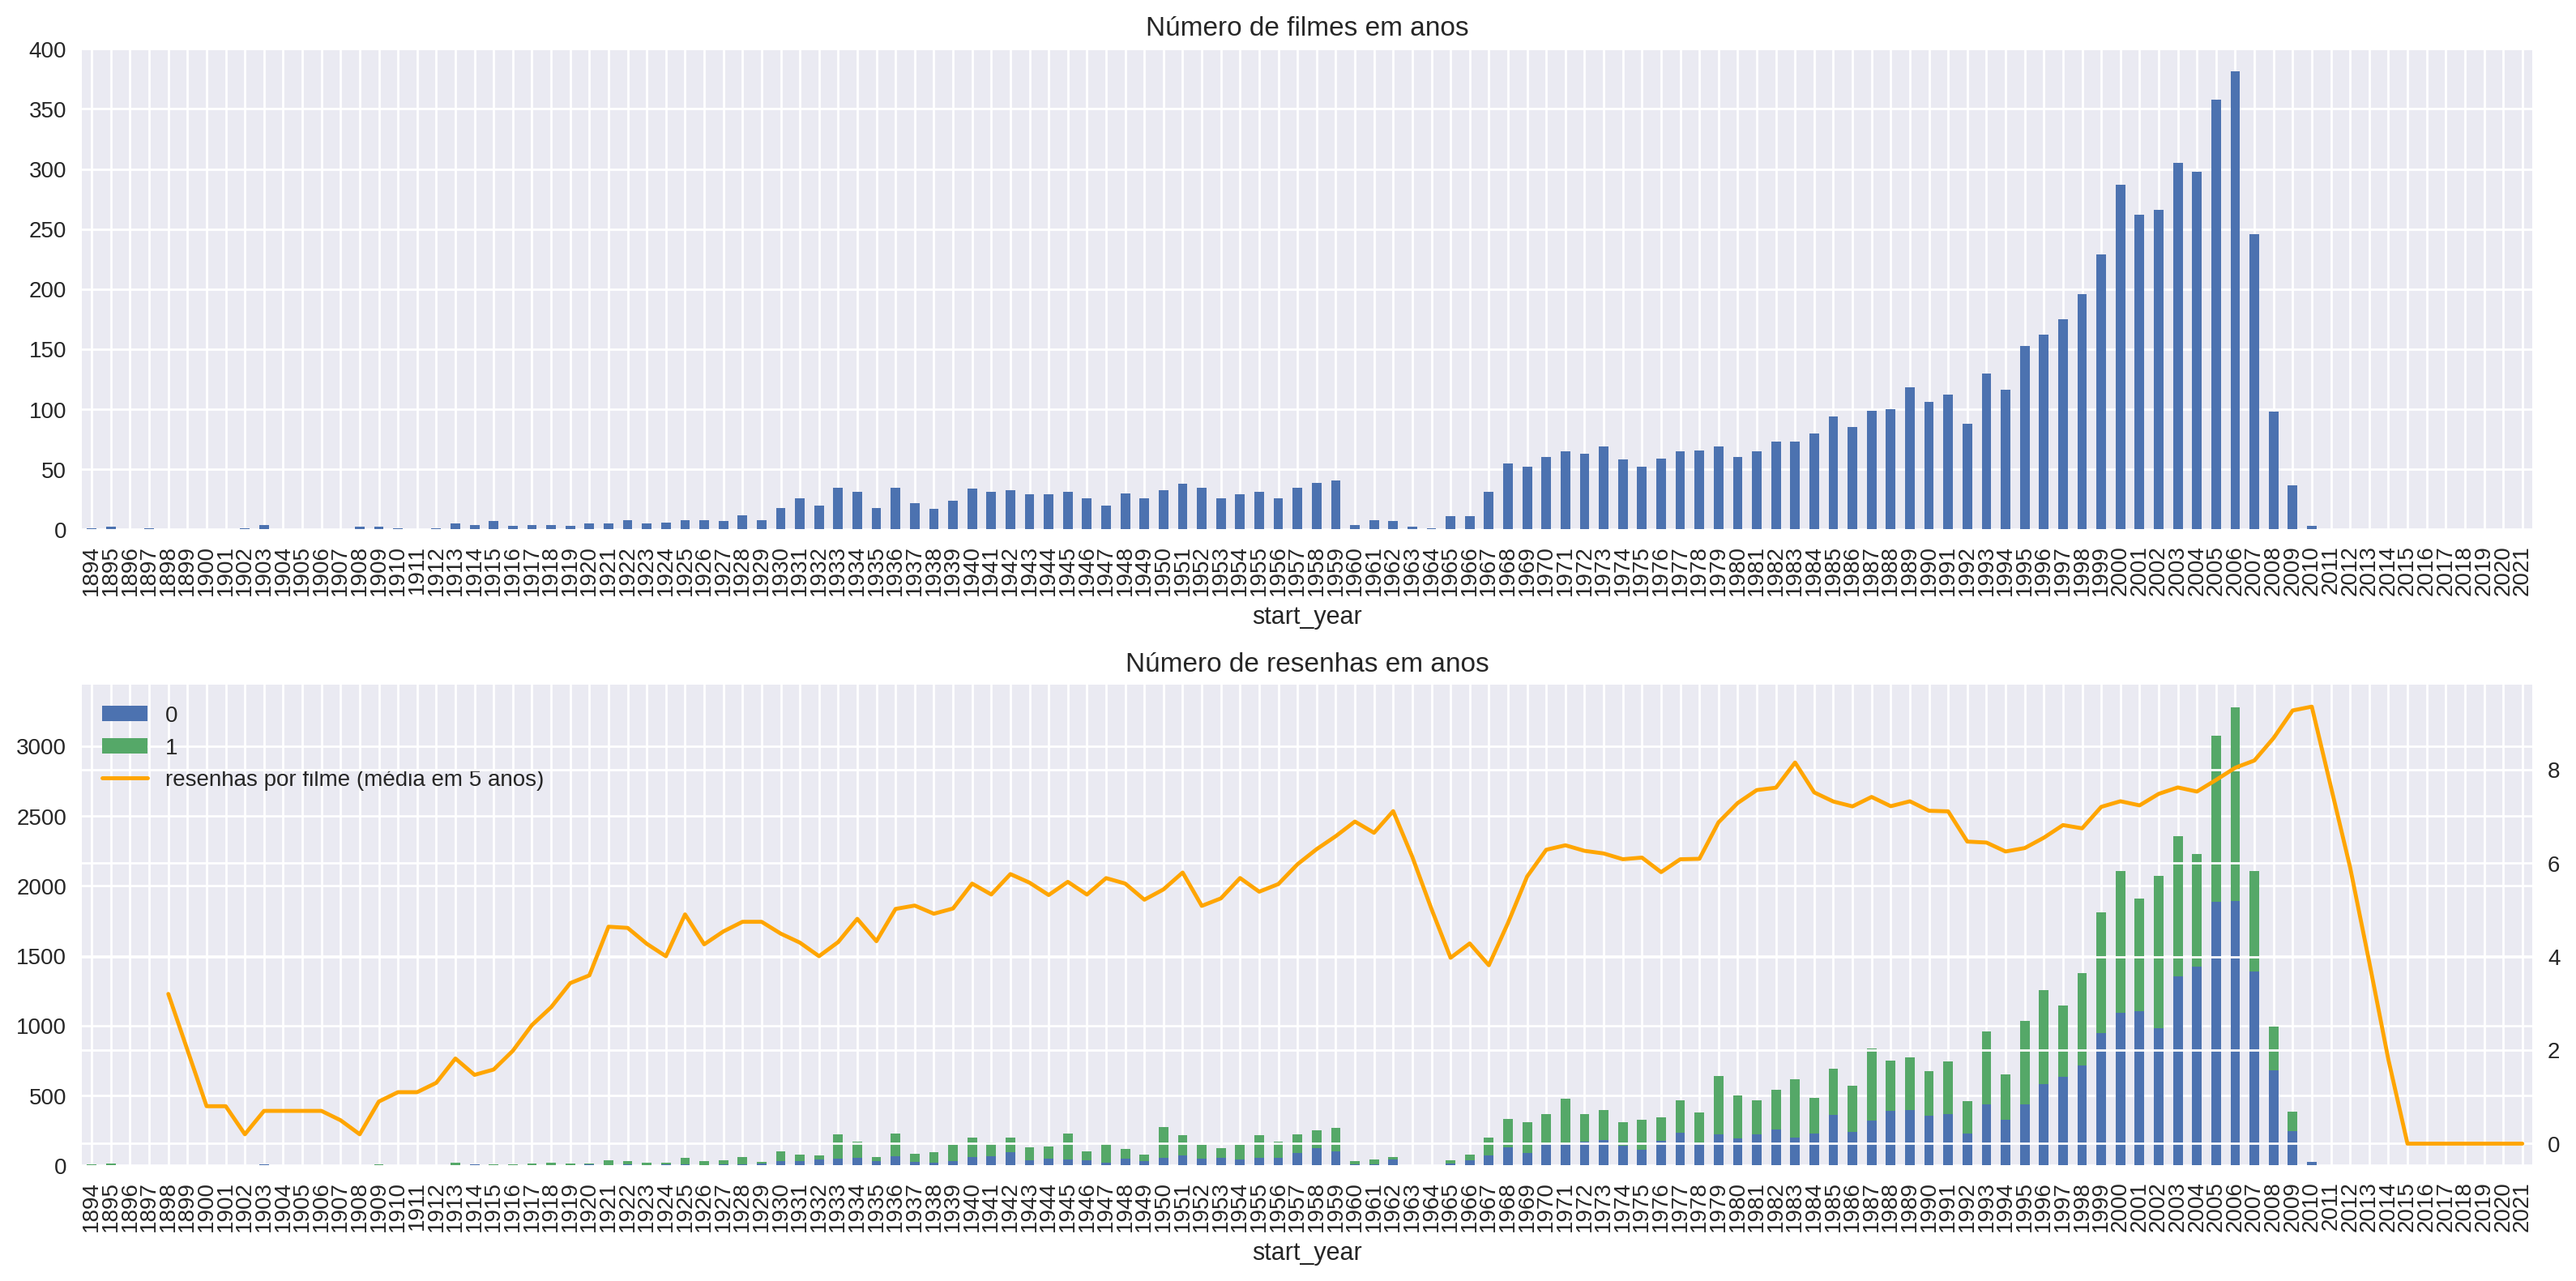

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

# --- GRÁFICO 1: Número de filmes por ano ---
ax = axs[0]

# Remove anos nulos e garante que são inteiros
df_clean = df_reviews.dropna(subset=['start_year']).copy()
df_clean['start_year'] = df_clean['start_year'].astype(int)

dft1 = df_clean[['tconst', 'start_year']].drop_duplicates()['start_year'].value_counts().sort_index()
anos = np.arange(dft1.index.min(), max(dft1.index.max(), 2021) + 1)

dft1 = dft1.reindex(index=anos).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de filmes em anos')

# --- GRÁFICO 2: Número de resenhas e média móvel ---
ax = axs[1]

dft2 = df_clean.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=anos).fillna(0)
dft2.plot(kind='bar', stacked=True, ax=ax)

dft2_total = df_clean['start_year'].value_counts().sort_index()
dft2_total = dft2_total.reindex(index=anos).fillna(0)

dft3 = (dft2_total / dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(
    color='orange',
    label='resenhas por filme (média em 5 anos)',
    ax=axt
)

# Junta as legendas das barras (ax) e da linha (axt)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = axt.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
legend = axt.get_legend()
if legend is not None:
    legend.remove()  # remove duplicated legend from the secondary axis, if it exists

ax.set_title('Número de resenhas em anos')

fig.tight_layout()
plt.show()

#### Entendendo os gráficos
- O primeiro gráfico de barras demonstra o número de filmes que possuem resenhas para cada ano
- O segundo, mostra quantas resenhas existem por ano, mas divede-os em duas barras: resenhas negativas (pos=0) e resenhas positivas (pos=1)
- Existe a linha de média móvel, para melhor ilustrar a tendência geral, suavizando picos e quedas de ano para ano.


Vamos verificar a distribuição do número de resenhas por filme com a contagem exata e o EDK (Estimativa de densidade kernel - só para saber como pode diferir da contagem exata)

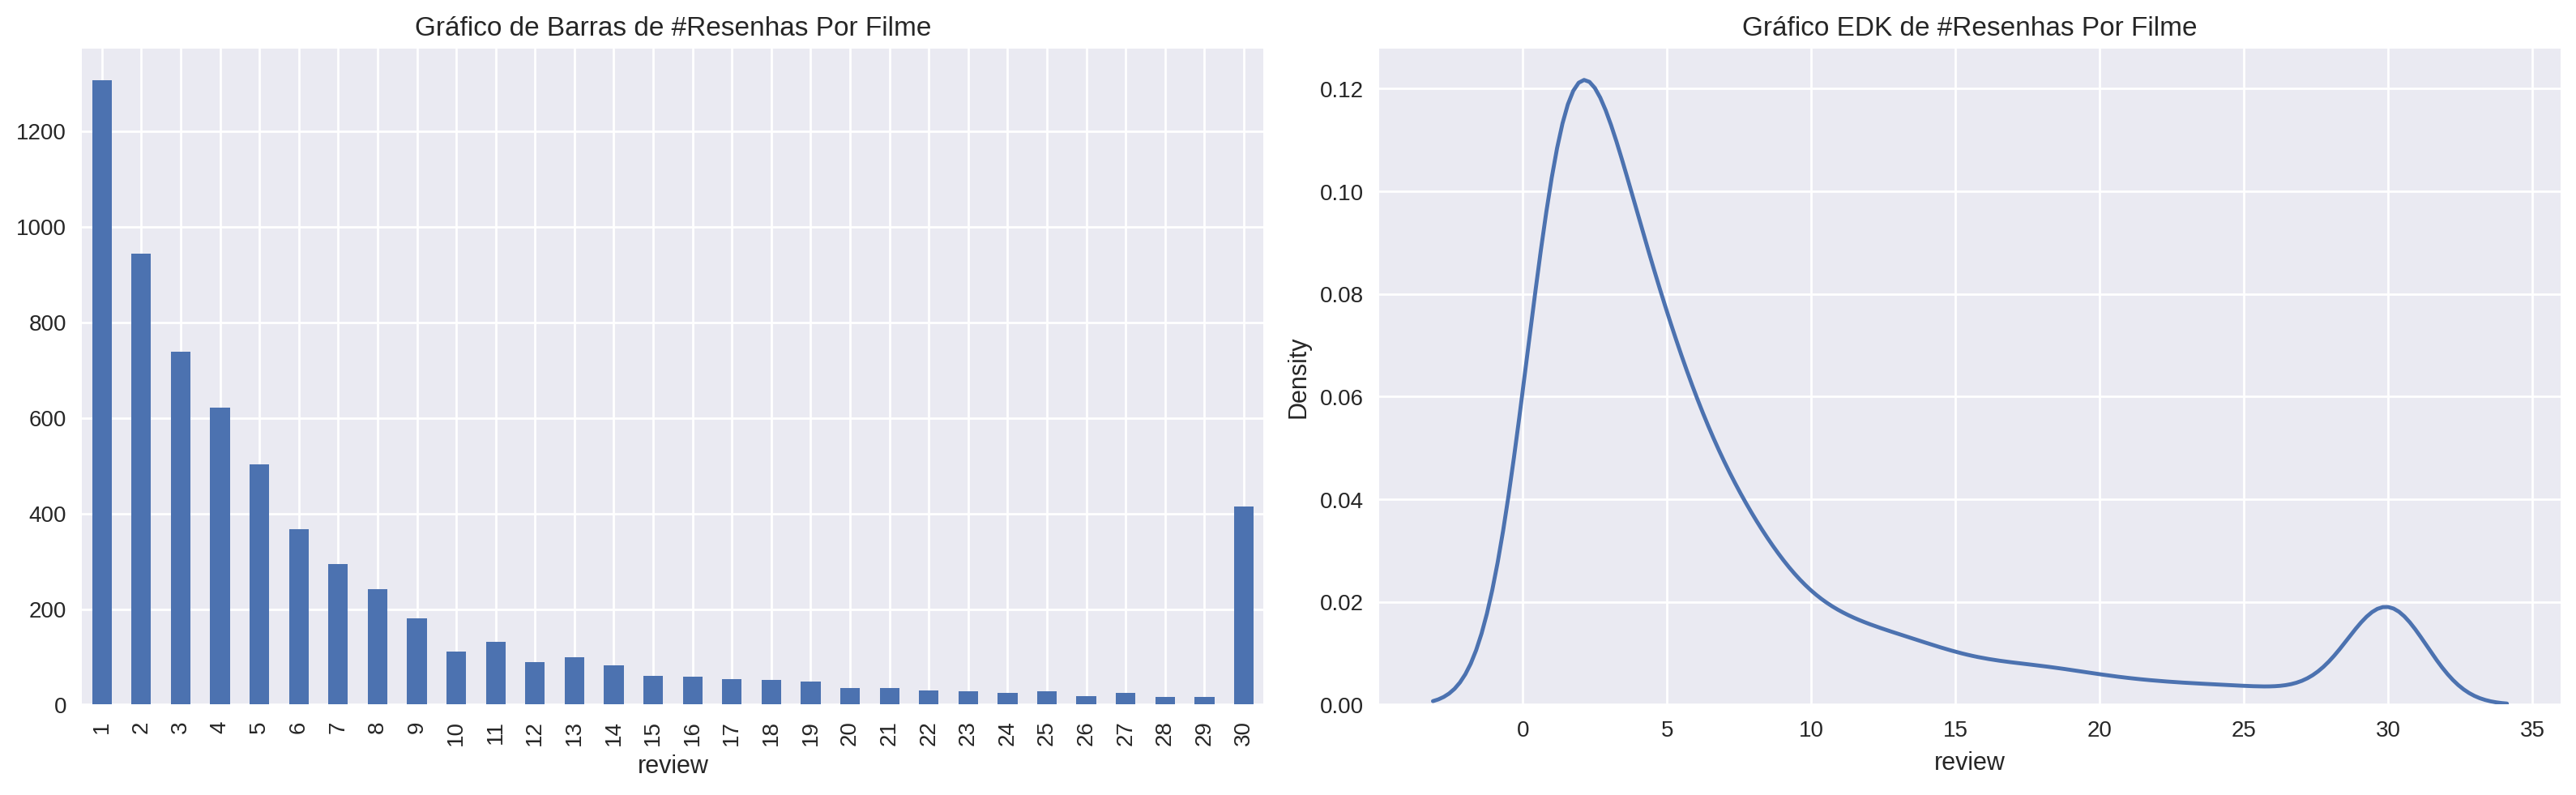

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de Barras de #Resenhas Por Filme')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico EDK de #Resenhas Por Filme')

fig.tight_layout()

- É importante frisar algo interessante nos nossos gráficos: Existe um pico distinto no valor 30 tanto no gráfico de barras quanto no KDE, o que sugere que reviews-per-movie pode ter sido limitado a 30 quando este conjunto de dados foi construído.

In [12]:
df_reviews['pos'].value_counts()

,count
pos,
0,23715
1,23616


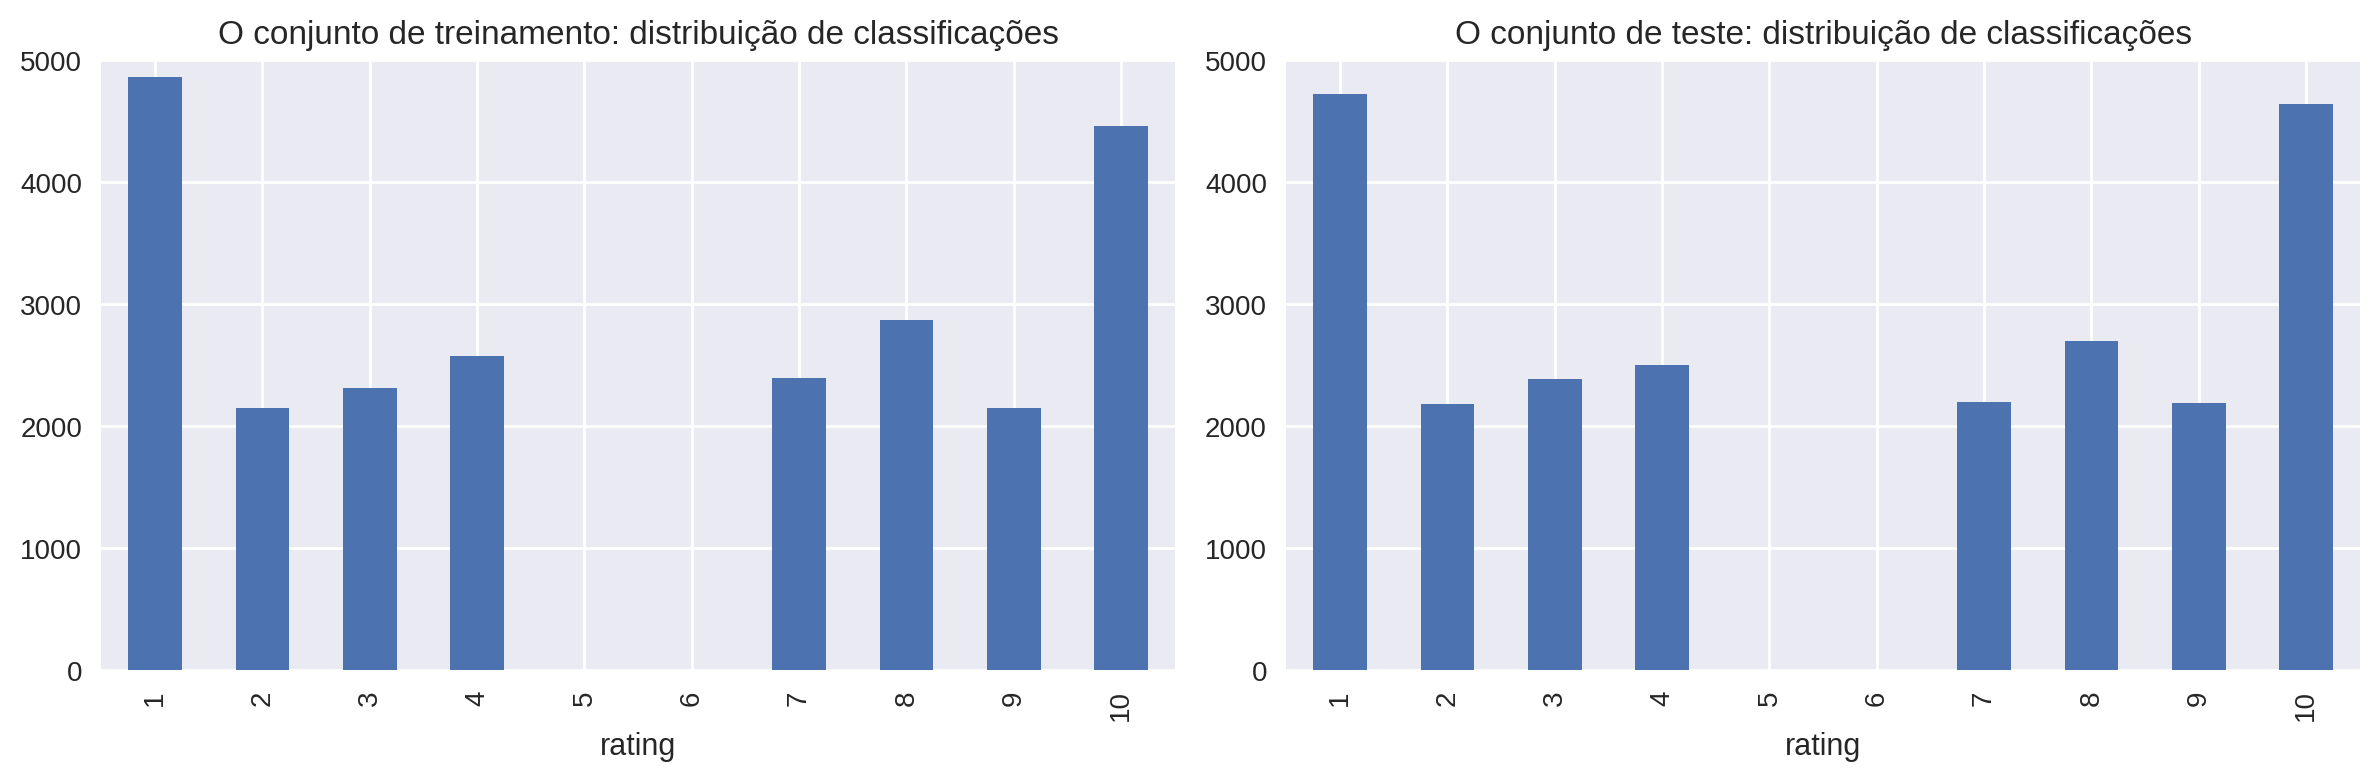

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de treinamento: distribuição de classificações')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de teste: distribuição de classificações')

fig.tight_layout()
plt.show()

##### Destaque interessante dos gráficos anteriores

- É importante ter em conta um aparticularidade no gráfico ácima:
- As notas nas bases de treino e teste, confirma-se uma consistência perfeita entre os dois conjuntos. A ausência completa de avaliações com notas 5 e 6, é um ponto de grande destaque. Esta característica reflete a metodologia de construção do dataset, onde pontuações média/neutras foram intencionalmente excluídas. Essa remoção artificial força uma clara divisão de polaridade (sentimento estritamente positivo ou negativo), eliminando ambiguidades e permitindo que algoritmos como a Regressão Logística, LightGBM e BERT foquem em padrões linguísticos de forte opinião

Distribuição de resenhas negativas e positivas ao longo dos anos para duas partes do conjunto de dados

/tmp/ipykernel_15598/1838910100.py:14: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/tmp/ipykernel_15598/1838910100.py:15: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
/tmp/ipykernel_15598/1838910100.py:30: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/tmp/ipykernel_15598/1838910100.py:31: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please updat

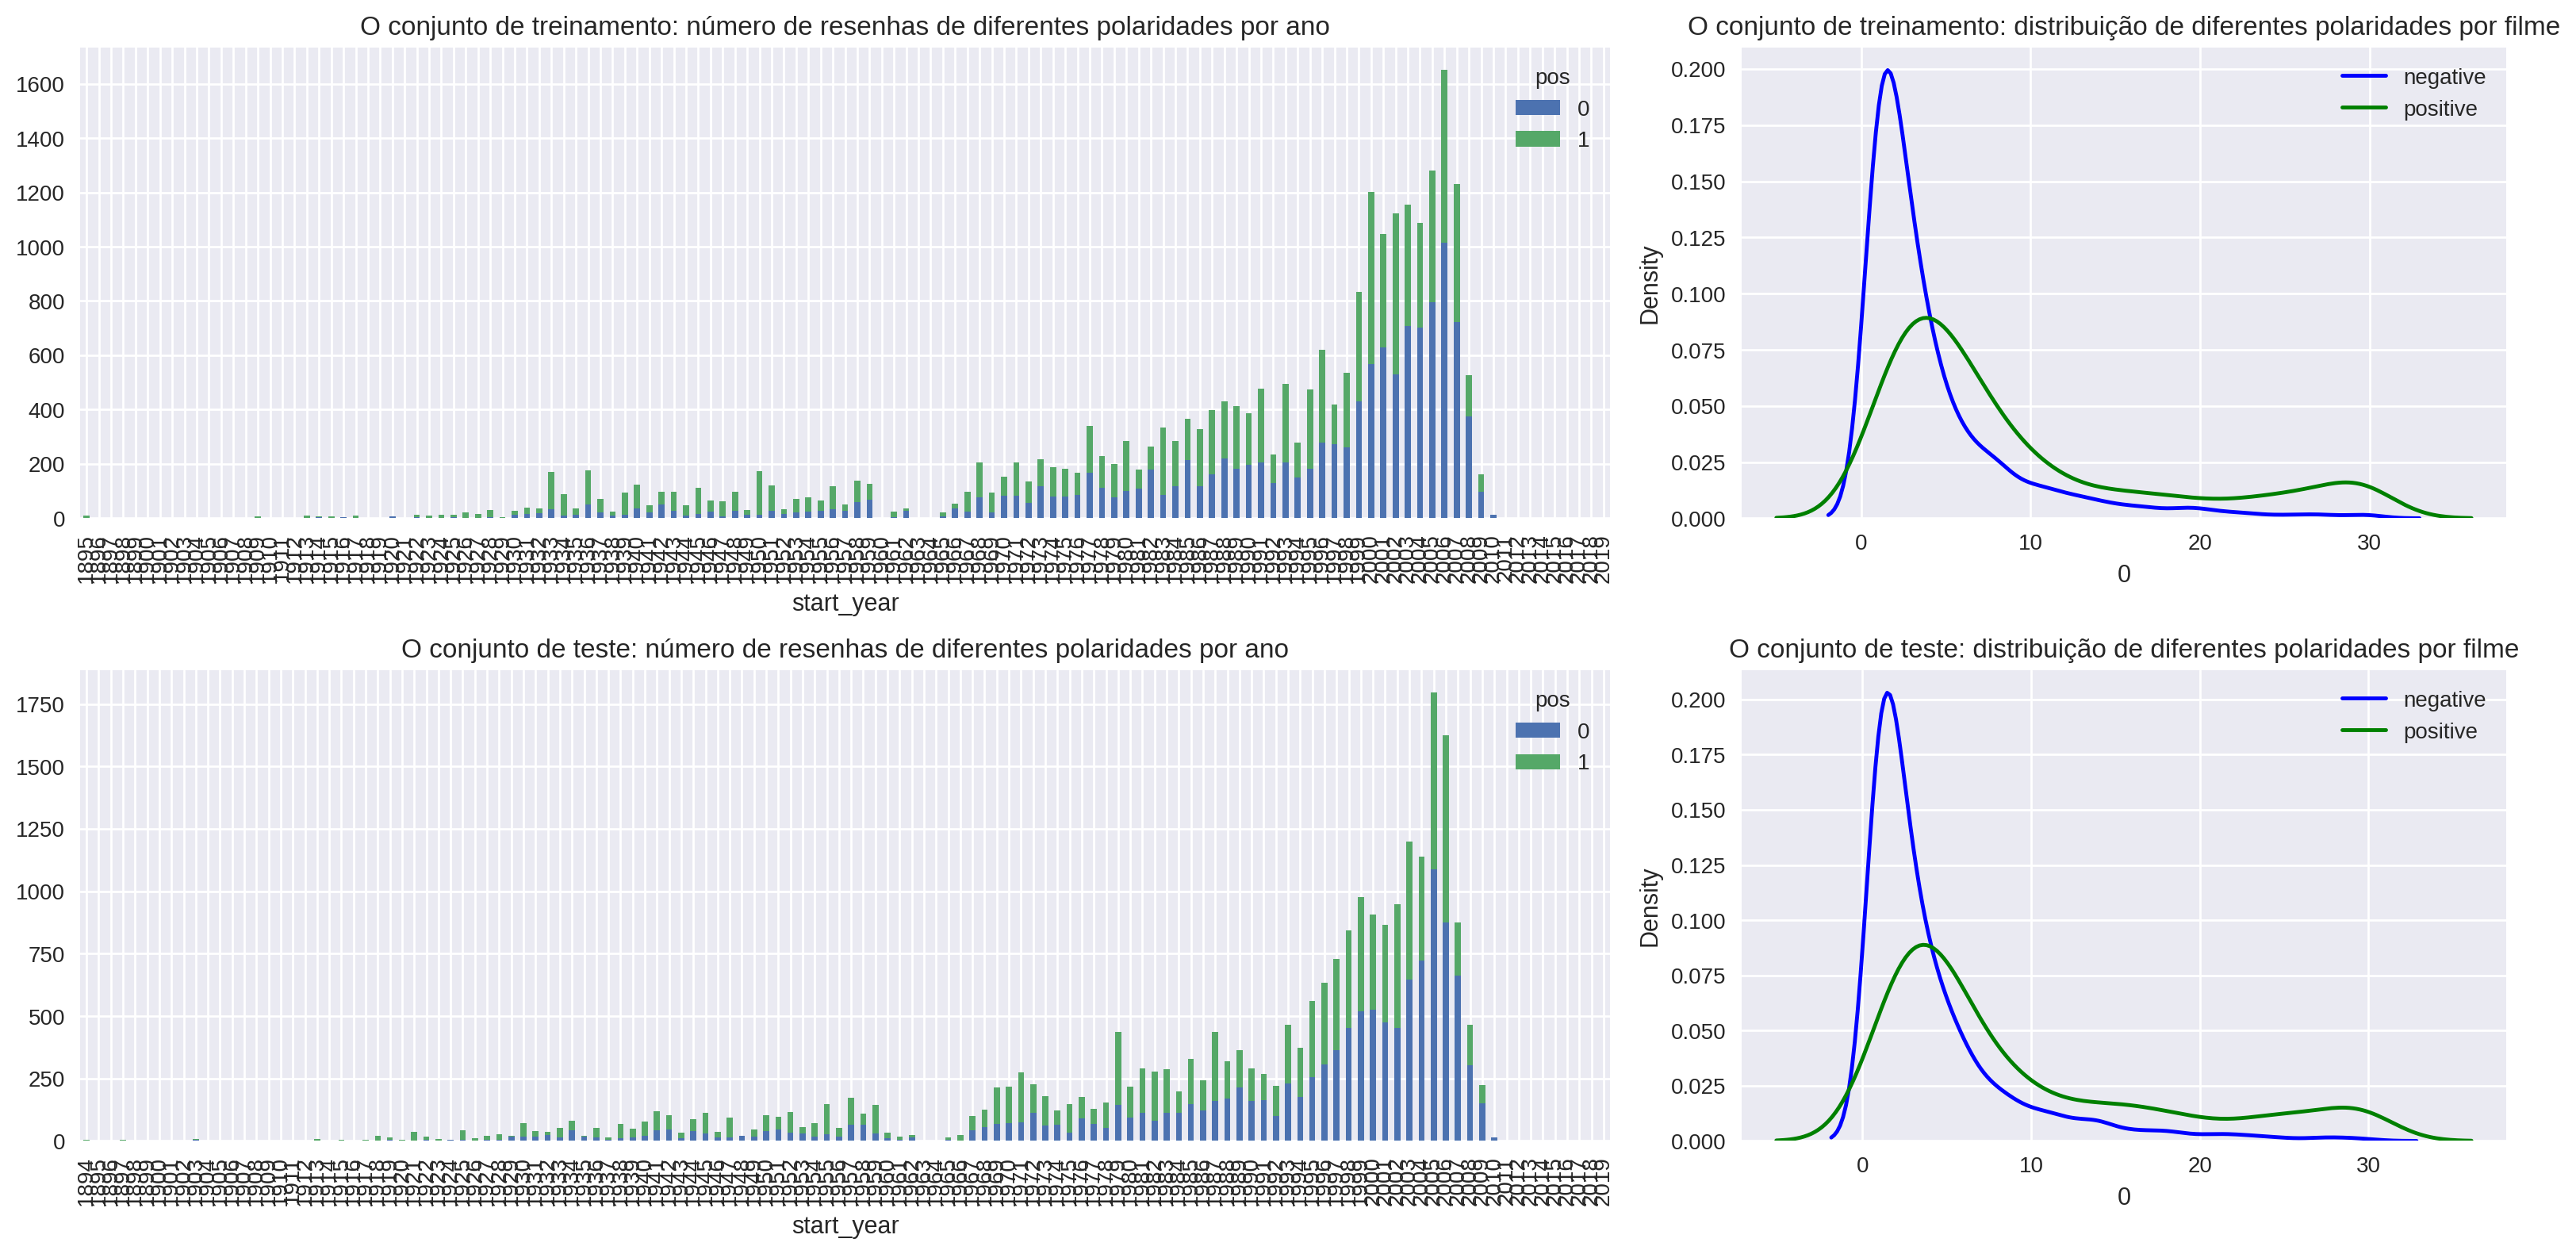

In [14]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de treinamento: número de resenhas de diferentes polaridades por ano')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('O conjunto de treinamento: distribuição de diferentes polaridades por filme')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de teste: número de resenhas de diferentes polaridades por ano')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('O conjunto de teste: distribuição de diferentes polaridades por filme')

fig.tight_layout()
plt.show()

#### Entendendo os gráficos ácima
- Separando o treino do teste, estes gráficos mostram uma análise muito parecida. Para este caso é importante verificar se ambos os conjuntos têm uma distribuição parecida, por ser importante para o modelo generalizar melhor
- Quantidade de resenhas por ano (para o treino)
- Quantidade de resenhas por ano (para o teste)
- Distribuição de resenhas por filme (treino)
- Distribuição de resenhas por filme (teste)

#### Conclusão da EDA
- Analisando os gráficos com os dados das duas classes, pode-se concluir que não existe nada de anormal ou de muito diferente entre as mesmas. O que quer dizer que estão muito equilibradas.
- As notas nas bases de treino e teste, confirma-se uma consistência perfeita entre os dois conjuntos. A ausência completa de avaliações com notas 5 e 6, é um ponto de grande destaque. Esta característica reflete a metodologia de construção do dataset, onde pontuações média/neutras foram intencionalmente excluídas.

## Procedimento de Avaliação

Compondo uma rotina de avaliação que pode ser utilizada para todos os modelos deste projeto

In [15]:
import sklearn.metrics as metrics

def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]


        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # Curva de precisão-revocação
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1')

        eval_stats[type]['F1'] = f1_scores[max_f1_score_idx]

        # ROC
        ax = axs[1]
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # setting crosses for some thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title(f'Curva ROC')

        # Curva de precisão-revocação
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # definindo cruzamentos para alguns limiares
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)


    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## Normalização

Assumimos que todos os modelos abaixo aceitam textos em letras minúsculas e sem dígitos, sinais de pontuação, etc.

In [16]:

df_reviews['review_norm'] = (
    df_reviews['review']
    .str.replace(r'<[^>]*>', ' ', regex=True) # removing HTML tags like ex.:<br />
    .str.lower()
    .str.replace(r"[^a-z'\s]", '', regex=True) # Mantém apenas letras de a-z, apóstrofos e espaços
    .str.replace(r'\s+', ' ', regex=True) # Substitui multiplos espaços por apenas um
    .str.strip()                         # Remove espaços extras no início e no fim
)



#### Entendendo a célula ácima
- Primeiro a criação de uma coluna review_norm
- Segundo a conversão para lower case
- Reenquandramento dos apostrofos de modos a não impactarem na leitura das contrações como "didn't"
- Remoção de tags HTML.

## Treinar / Testar Conjunto

Felizmente, todo o conjunto de dados já está dividido em partes de treinamento/teste. A opção correspondente é 'ds_part'.

In [17]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


#### Entendendo a célula ácima
- Divisão dos dados em dois: treino e teste (23796, 18 - 23535, 18)

## Trabalhando com modelos

### Modelo 0 - Constante

In [18]:
from sklearn.dummy import DummyClassifier

In [19]:
model_0 = DummyClassifier(strategy='most_frequent', random_state=42) # Criar o modelo com a estratégia definida

In [20]:
model_0.fit(df_reviews_train['review_norm'], train_target) # Treinar o modelo

DummyClassifier(random_state=42, strategy='most_frequent')

          train  test
Accuracy   0.50  0.50
F1         0.67  0.67
APS        0.50  0.50
ROC AUC    0.50  0.50


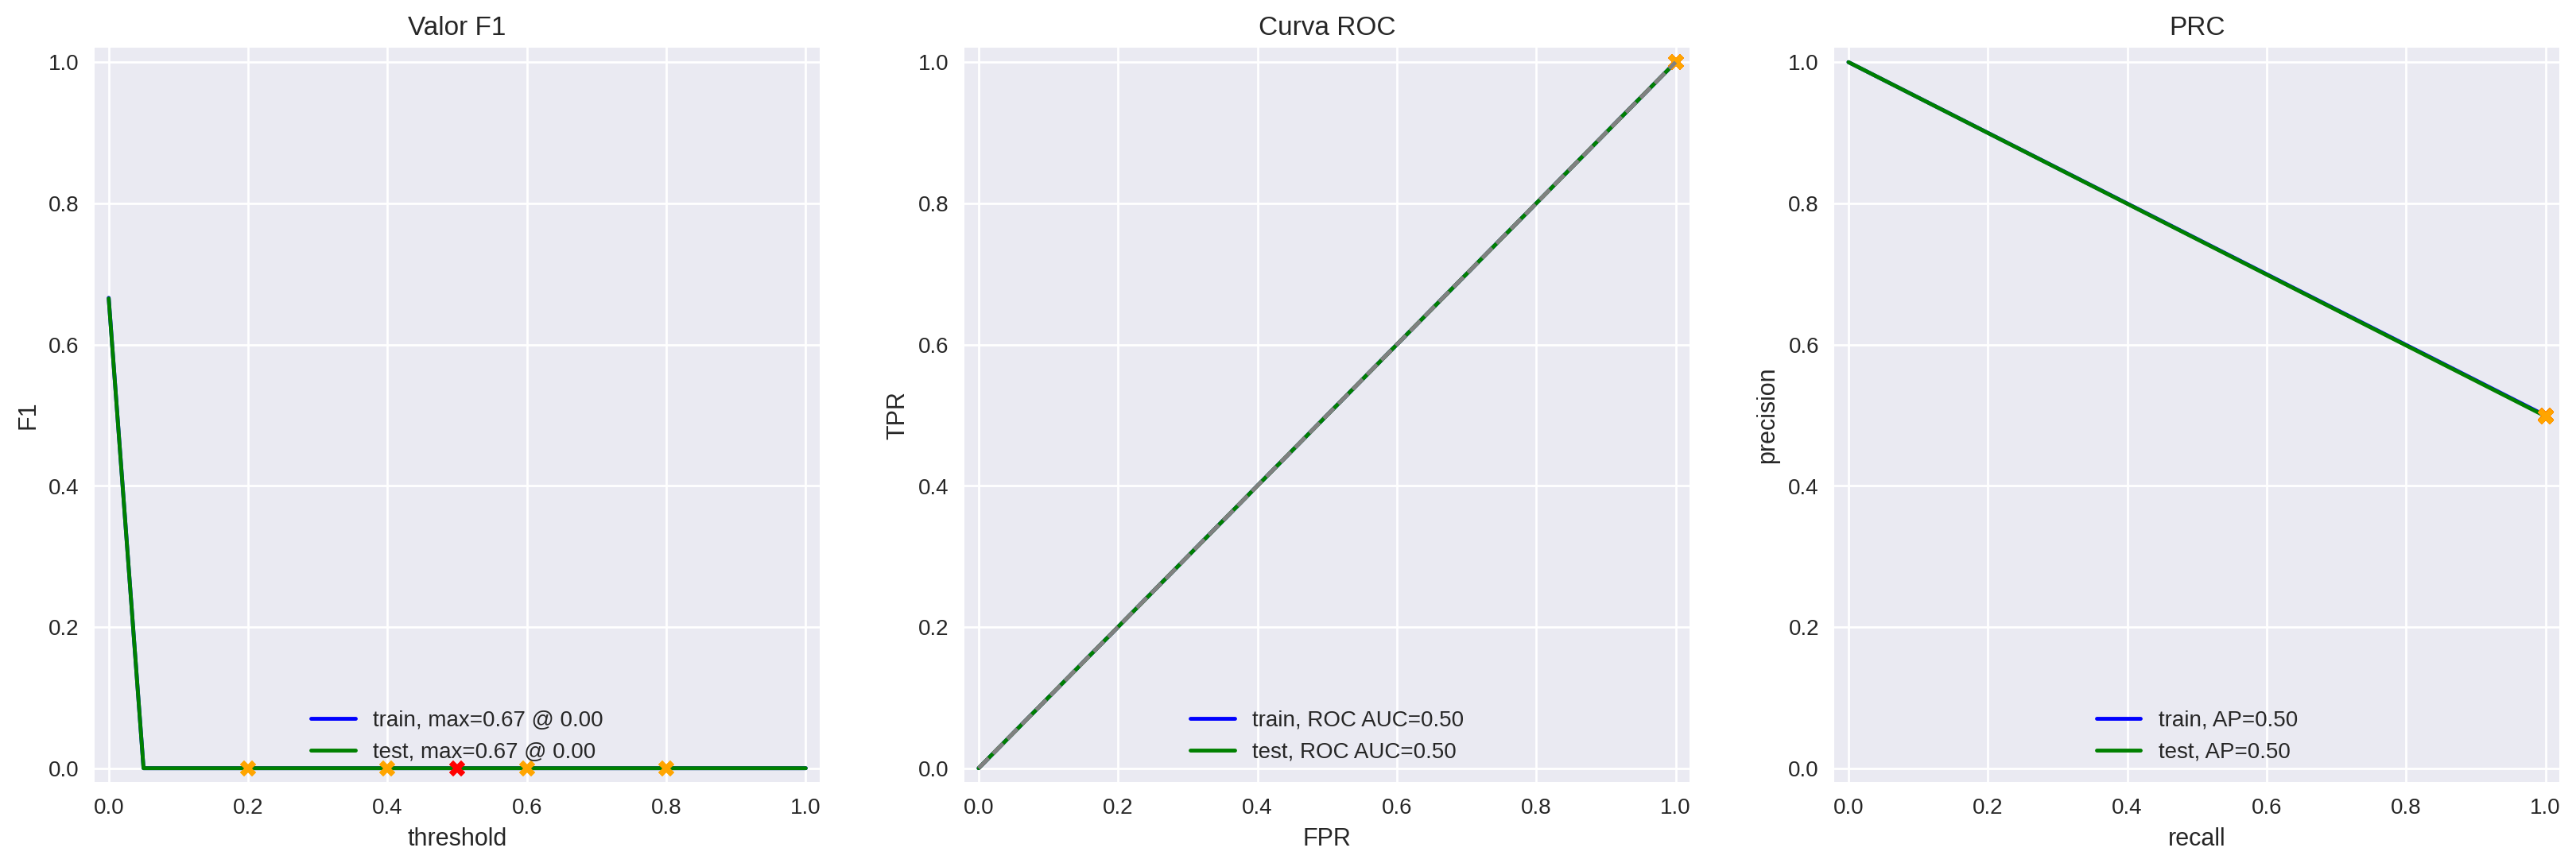

In [21]:
evaluate_model(model_0, df_reviews_train['review_norm'], train_target, df_reviews_test['review_norm'], test_target)

### Modelo 1 - NLTK, TF-IDF e Regressão Linear

TF-IDF

In [22]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

In [23]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [24]:
pal_irrelevantes = stopwords.words('english') # 1. Configurar a lista de stopwords em eng
vetorizador = TfidfVectorizer(
    stop_words=pal_irrelevantes,
    max_features=5000,
    ngram_range=(1, 2)
) # Instanciar o vetorizador com os parametros ajustados

In [25]:
model_1=LogisticRegression(max_iter=1000, random_state=42)

In [26]:
start_time = time.time() # Caprtura o tempo inicial antes do treino

train_features_1 = vetorizador.fit_transform(df_reviews_train['review_norm']) # Mapear o vocabulário e transformar o texto de treino
test_features_1 = vetorizador.transform(df_reviews_test['review_norm']) # Apenas transformar o texto de teste (não aprende de novo)
model_1.fit(train_features_1, train_target)

end_time = time.time() # Captura o tempo final após a conclusãodo treino

tempo_execucao = end_time - start_time

In [27]:
print(f"Tempo total de execução: {tempo_execucao / 60:.2f} minutos")

Tempo total de execução: 0.31 minutos


          train  test
Accuracy   0.92  0.88
F1         0.92  0.88
APS        0.97  0.95
ROC AUC    0.97  0.95


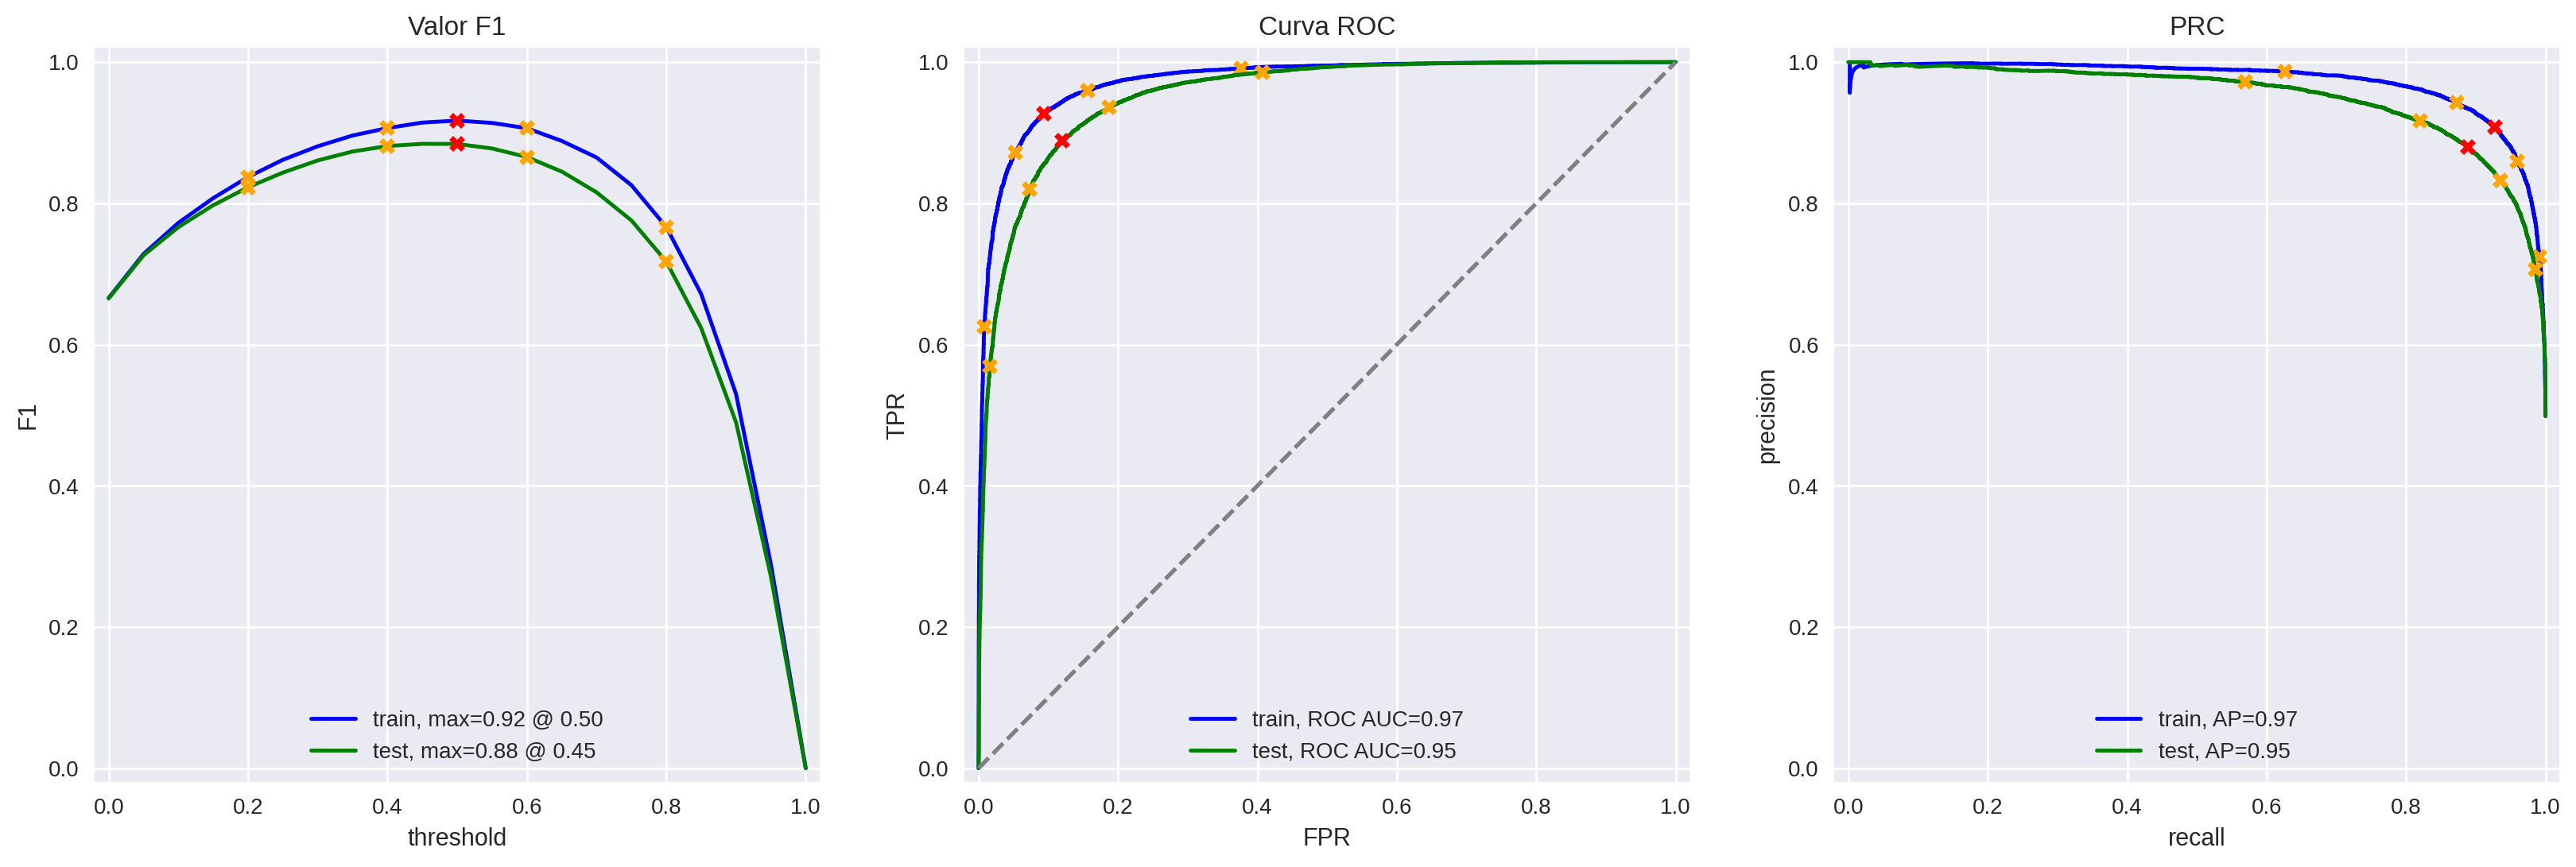

In [28]:
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

#### Entendendo as células anteriores
- Grande progresso o Modelo 1(TF-IDF + Regressão Logística) foi treinado e avaliado com os seguintes resultados: F1 treino:0.92 e teste:0.88
- A condição inicial deste projecto é que os modelos pudessem atingir pelo menos F1 = 0.85

### Modelo 2 - spaCy, TF-IDF e Regressão Linear

In [29]:
# Resolução de problemas com o spaCy

import spacy
print(spacy.__version__)
import sys
!{sys.executable} -m pip install --user https://github.com

3.8.18
     - 525.7 kB 90.1 MB/s 0:00:00
  ERROR: Cannot unpack file /tmp/pip-unpack-gprwpmrp/github.com (downloaded from /tmp/pip-req-build-3nblu5on, content-type: text/html; charset=utf-8); cannot detect archive format
ERROR: Cannot determine archive format of /tmp/pip-req-build-3nblu5on


In [30]:

class SpacyTextProcessor:
    def __init__(self, model_name="en_core_web_sm"):
        try:
            self._nlp = spacy.load(model_name, disable=["parser", "ner"])
        except OSError:
            print(f"Model '{model_name}' not found. Downloading...")
            subprocess.check_call([sys.executable, "-m", "spacy", "download", model_name])
            self._nlp = spacy.load(model_name, disable=["parser", "ner"])

    def __call__(self, text):
        return self._nlp(text)

    def __getattr__(self, name):
        return getattr(self._nlp, name)

nlp = SpacyTextProcessor()



In [31]:
import subprocess, sys

resultado = subprocess.run(
    [sys.executable, "-m", "spacy", "download", "en_core_web_sm", "--user"],
    capture_output=True,
    text=True
)
print("ERRO REAL:", resultado.stderr)

ERRO REAL: 


In [32]:
#pip install https://github.com

In [33]:
def text_preprocessing_2(text):

    doc = nlp(text)
    tokens = [token.lemma_ for token in doc if not token.is_stop]
    #tokens = [token.lemma_ for token in doc]

    return ' '.join(tokens)

In [34]:
print("Vectorizando o texto processado")
pal_irrelevantes_2 = stopwords.words('english') # 1. Configurar a lista de stopwords em Inglês
vetorizador_2 = TfidfVectorizer(
    stop_words=pal_irrelevantes_2,
    max_features=5000,
    ngram_range=(1, 2)
) # Instanciar o vetorizador com os parametros ajustados

Vectorizando o texto processado


In [35]:
model_2 = LogisticRegression(max_iter=1000, random_state=42)

In [36]:
df_reviews_train['review_norm_2'] = df_reviews_train['review'].apply(text_preprocessing_2)
df_reviews_test['review_norm_2'] = df_reviews_test['review'].apply(text_preprocessing_2)

In [37]:
start_time_2 = time.time() # Captura do tempo inicial antes do treino

train_features_2 = vetorizador_2.fit_transform(df_reviews_train['review_norm_2']) # Mapear o vocabulário e transformar o texto de treino
test_features_2 = vetorizador_2.transform(df_reviews_test['review_norm_2']) # Apenas transformar o texto de teste (não aprende de novo)
model_2.fit(train_features_2, train_target)

end_time_2 = time.time()
tempo_2_execucao = end_time_2 - start_time_2

In [38]:
print(f"Tempo total de execução: {tempo_2_execucao / 60:.2f} minutos")

Tempo total de execução: 0.24 minutos


Vamos avaliar o Modelo
          train  test
Accuracy   0.91  0.87
F1         0.91  0.88
APS        0.97  0.94
ROC AUC    0.97  0.95


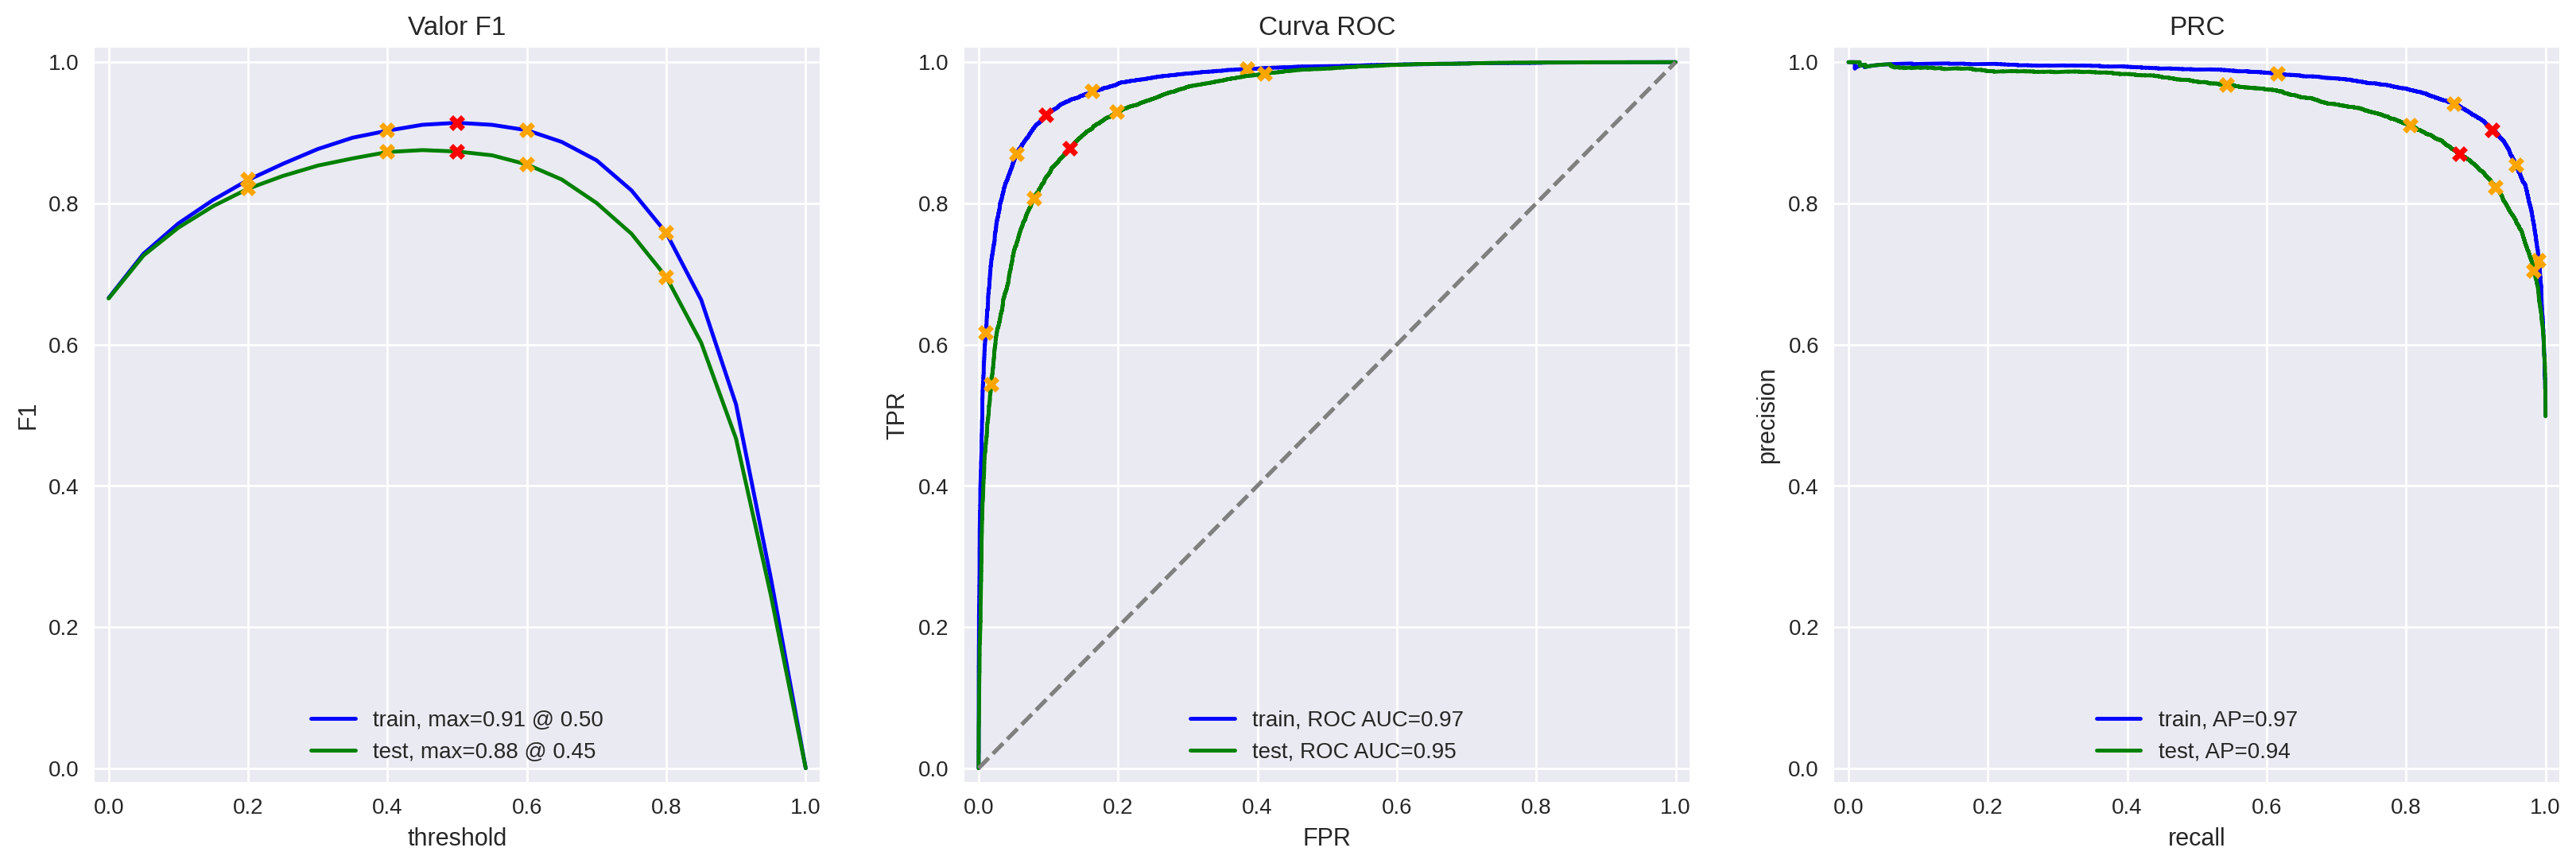

In [39]:

print("Vamos avaliar o Modelo")
evaluate_model(model_2, train_features_2, train_target, test_features_2, test_target)


In [40]:
print(len(vetorizador.vocabulary_))
print(len(vetorizador_2.vocabulary_))
#print(vetorizador.get_feature_names_out()[:20])
#print(vetorizador_3.get_feature_names_out()[:20])

print(type(vetorizador))
print(df_reviews_train['review_norm'].iloc[0][:200])
print(df_reviews_train['review_norm_2'].iloc[0][:200])


5000
5000
<class 'sklearn.feature_extraction.text.TfidfVectorizer'>
the pakage implies that warren beatty and goldie hawn are pulling off a huge bank robbery but that's not what i got out of it i didn't get anything in the first half there's a new character without in
pakage imply Warren Beatty Goldie Hawn pull huge bank robbery , get ! ! half new character ( introduction ) scene . half - hour completely incomprehensible , rest long , annoying , underlit chase scen


<div class="alert alert-block alert-warning">
Bom instinto ao comparar tamanhos de vocabulário e texto normalizado entre `review_norm` e `review_norm_2`. Pequena limpeza: a linha comentada referenciando `vetorizador_3` aponta para uma variável que não existe em nenhum lugar deste notebook e pode ser removida.
</div>

#### Entendendo as células
- Grande progresso o Modelo 2(Spacy + TF-IDF + Regressão Logística) foi treinado e avaliado com os seguintes resultados: F1 treino:0.91 e teste:0.88
- A condição inicial deste projecto é que os modelos pudessem atingir pelo menos F1 = 0.85


### Modelo 3 - SpaCy, TF-IDF e LGBMClassifier

In [41]:

from lightgbm import LGBMClassifier


In [42]:
# Criando o modelo com os parâmetros mais comuns

model_3 = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=42
)

<div class="alert alert-block alert-warning">
Boa escolha trazer gradient boosting como uma família de modelos genuinamente diferente. Os hiperparâmetros que você escolheu são seleções manuais razoáveis, mas não foram sintonizados — uma varredura rápida com `GridSearchCV`/`RandomizedSearchCV` sobre `learning_rate`, `num_leaves` e `n_estimators` poderia ajudar a fechar a lacuna restante até a meta de F1 para este modelo.
</div>

In [43]:
# Treinando apenas o modelo e abdicando da transformação dos dados, porque estamos a usar os mesmos dados do model_2
model_3.fit(train_features_2, train_target)

[LightGBM] [Info] Number of positive: 11884, number of negative: 11912
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.323783 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 412172
[LightGBM] [Info] Number of data points in the train set: 23796, number of used features: 4997
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499412 -> initscore=-0.002353
[LightGBM] [Info] Start training from score -0.002353


LGBMClassifier(learning_rate=0.05, random_state=42)

Vamos avaliar o Modelo


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


          train  test
Accuracy   0.87  0.83
F1         0.87  0.84
APS        0.94  0.92
ROC AUC    0.94  0.92


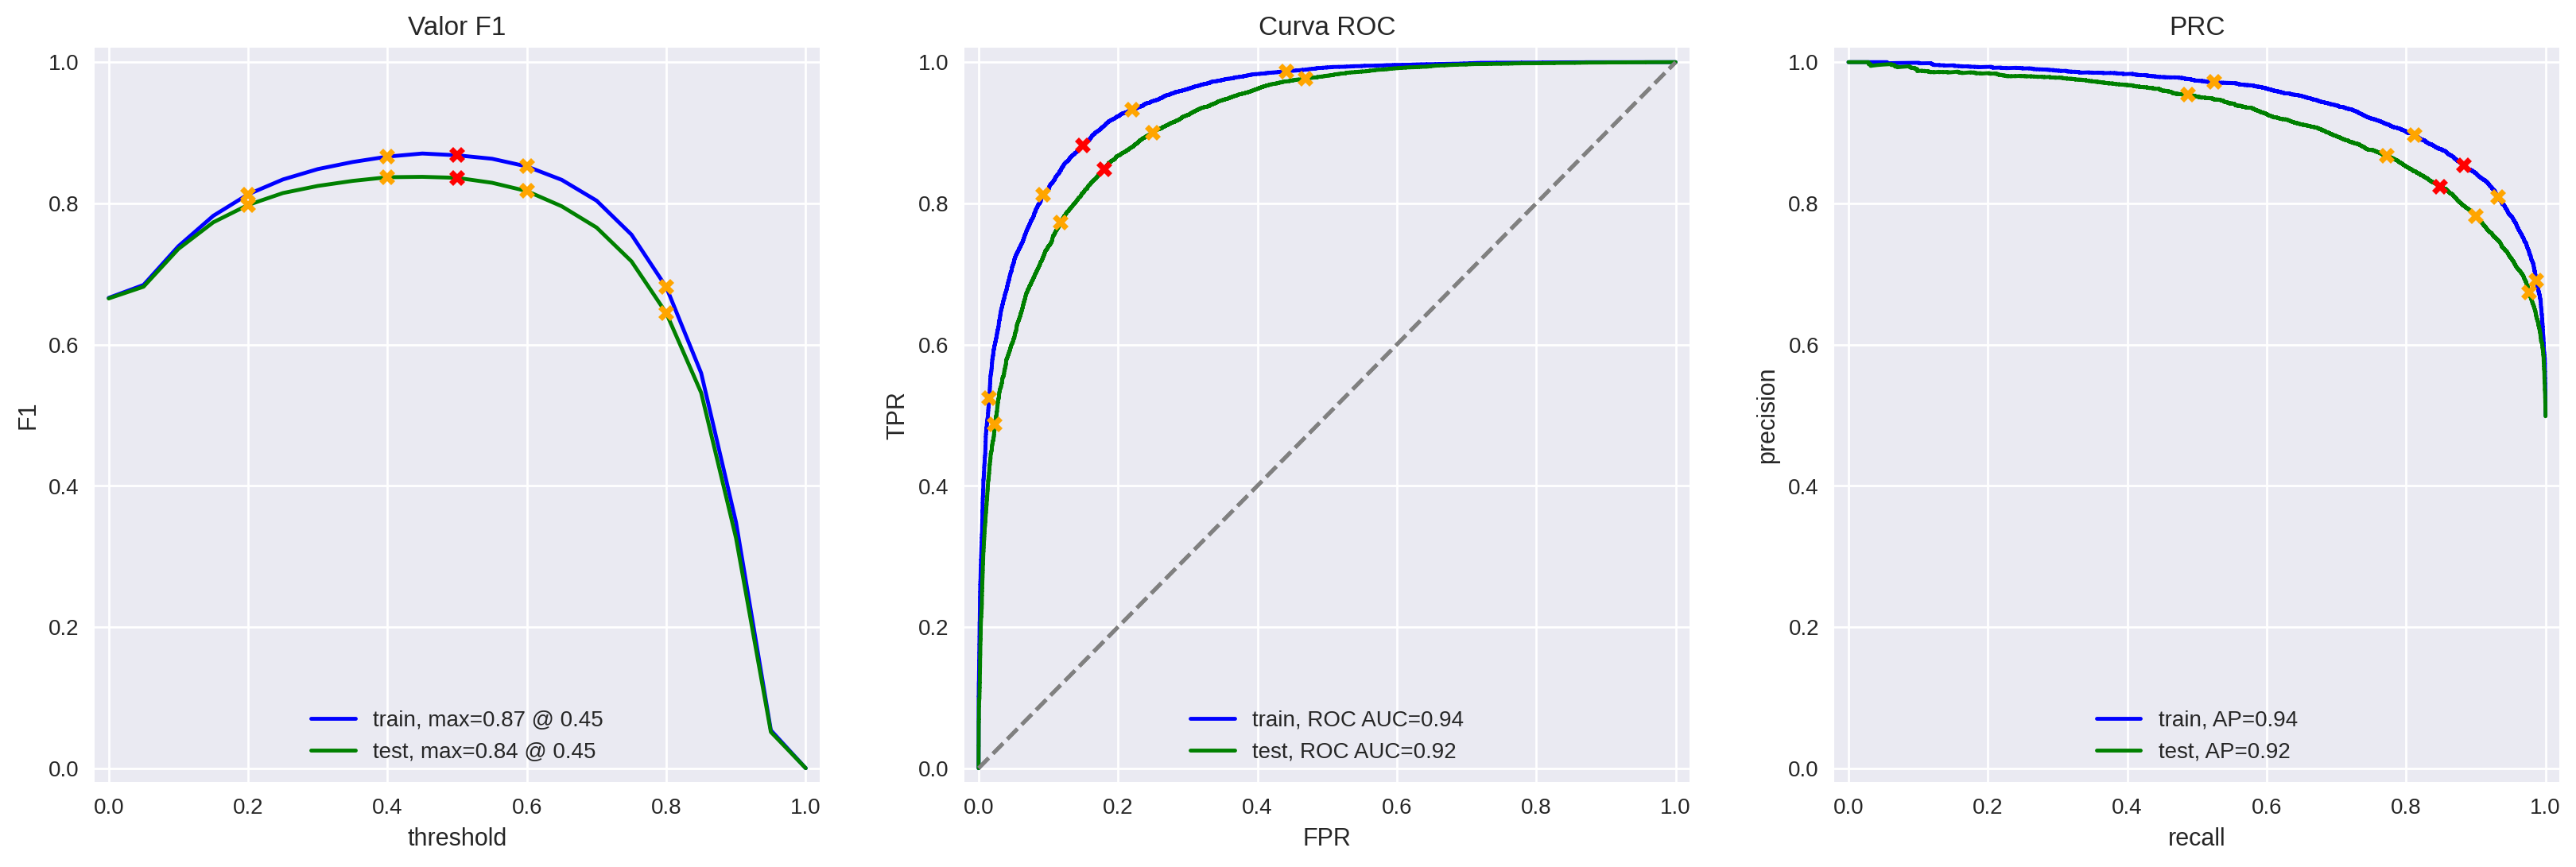

In [44]:
print("Vamos avaliar o Modelo")
evaluate_model(model_3, train_features_2, train_target, test_features_2, test_target)

<div class="alert alert-block alert-warning">
Esta avaliação funciona sem problemas e as curvas plotadas correspondem à tabela impressa (F1 = 0,87/0,84, ROC AUC 0,94/0,92). Vale a pena mencionar explicitamente em sua redação: isoladamente, o F1 de teste deste modelo (0,84) fica ligeiramente abaixo do limite de 0,85 do projeto, mesmo que seus outros modelos já o ultrapassem.
</div>

###  Modelo 4 - BERT

In [45]:
import torch
import transformers
from sklearn.ensemble import RandomForestClassifier

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [46]:
tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
config = transformers.BertConfig.from_pretrained('bert-base-uncased')
model = transformers.BertModel.from_pretrained('bert-base-uncased')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [47]:

def BERT_text_to_embeddings(texts, max_length=128, batch_size=16, force_device=None, random_state = 42, disable_progress_bar=False):

    ids_list = []
    attention_mask_list = []

    # texto para IDs de tokens preenchidos com suas máscaras de atenção
    for text in texts:
        encoded = tokenizer.encode_plus(
            text,
            add_special_tokens=True,    # Adiciona os tokens [CLS] e [SEP]
            max_length=max_length,      # Limita o tamanho fixo (ex: 128)
            padding='max_length',       # Preenche com 0s se for menor
            truncation=True,            # Corta se for maior que o max_length
            return_attention_mask=True  # Gera a máscara de 0s e 1s
        )
        ids_list.append(encoded['input_ids'])
        attention_mask_list.append(encoded['attention_mask'])

    # <coloque seu código aqui para criar ids_list e attention_mask_list>


    if force_device is not None:
        device = torch.device(force_device)
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model.to(device)
    if not disable_progress_bar:
        print(f'Usando o dispositivo {device}.')

    # recebendo incorporações em lotes

    embeddings = []

    for i in tqdm(range(math.ceil(len(ids_list)/batch_size)), disable=disable_progress_bar):

        ids_batch = torch.LongTensor(ids_list[batch_size*i:batch_size*(i+1)]).to(device)
        # <coloque seu código aqui para criar attention_mask_batch
        attention_mask_batch = torch.LongTensor(attention_mask_list[batch_size*i : batch_size*(i+1)]).to(device)
        with torch.no_grad():
            model.eval()
            batch_embeddings = model(input_ids=ids_batch, attention_mask=attention_mask_batch)
        embeddings.append(batch_embeddings[0][:,0,:].detach().cpu().numpy())

        if device.type == 'cuda':
            torch.cuda.empty_cache()

    return np.concatenate(embeddings)


#### Alterações dos parâmetros
- É muito difícil rodar o BERT, principalmente com parâmetros muito altos, porque exige bastande do hardware
- Neste caso com lotes de 100 textos e sequências de tamanho 512 consome a memória toda e pode parar o sistema, quando se trata da maioria das GPUs comerciais. Devemos ter cuidado quando encaramos estes cenários. Mas este era apenas um pior caso hipotético.
- A função executada na realidade foi 128/16
- Para se resolver o problema, para que o código corra até ao fim, é necessário efectuar alguns ajustes estratégicos como: redução drástica do tamanho do lote, diminuição do tamanho máximo da sequência e 'release' de memória cache da CPU

In [48]:
df_amostra_tr = df_reviews_train.sample(350)
df_amostra_ts = df_reviews_test.sample(350)

<div class="alert alert-block alert-warning">
`df_reviews_train.sample(350)` e `df_reviews_test.sample(350)` ainda não definem um `random_state`. Isso significa que uma subamostra diferente de 350 avaliações é extraída a cada vez que o notebook é executado, portanto todas as métricas BERT posteriores e probabilidades mudam de execução para execução — o que é por que alguns números citados posteriormente em suas conclusões não correspondem mais ao resultado real desta execução. Adicionar `random_state=42` aqui, como você fez para seus outros modelos, corrigiria isso e tornaria seus resultados BERT reproduzíveis.
</div>

In [49]:
# Train
train_target_BERT = df_amostra_tr['pos']
train_features_BERT = df_amostra_tr['review_norm']
# Test
test_target_BERT = df_amostra_ts['pos']
test_features_BERT = df_amostra_ts['review_norm']
#Convertendo para lista
train_features_BERT = train_features_BERT.tolist()
test_features_BERT = test_features_BERT.tolist()

In [50]:
#!pip install transformers==4.46.3

In [51]:
# Atenção! A execução do BERT para milhares de textos pode levar muito tempo na CPU, pelo menos várias horas
train_features_BERT = BERT_text_to_embeddings(train_features_BERT,
                                           force_device=None #cuda
                                          )

Usando o dispositivo cuda.


  0%|          | 0/22 [00:00<?, ?it/s]

In [52]:
# Atenção! A execução do BERT para milhares de textos pode levar muito tempo na CPU, pelo menos várias horas
test_features_BERT = BERT_text_to_embeddings(test_features_BERT,
                                           force_device=None #cuda
                                          )

Usando o dispositivo cuda.


  0%|          | 0/22 [00:00<?, ?it/s]

In [53]:
# Criar o modelo usando LGBM Classifier
model_4_clf = LGBMClassifier(
    n_estimators=20,
    learning_rate=0.05,
    num_leaves=2,
    max_depth=2,
    min_child_samples=8,
    n_jobs=-5,
    random_state=42
)
# Treinando o modelo
model_4_clf.fit(train_features_BERT, train_target_BERT)

[LightGBM] [Info] Number of positive: 180, number of negative: 170
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011044 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 90150
[LightGBM] [Info] Number of data points in the train set: 350, number of used features: 768
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.514286 -> initscore=0.057158
[LightGBM] [Info] Start training from score 0.057158


LGBMClassifier(learning_rate=0.05, max_depth=2, min_child_samples=8,
               n_estimators=20, n_jobs=-5, num_leaves=2, random_state=42)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


          train  test
Accuracy   0.77  0.65
F1         0.78  0.66
APS        0.85  0.64
ROC AUC    0.85  0.70


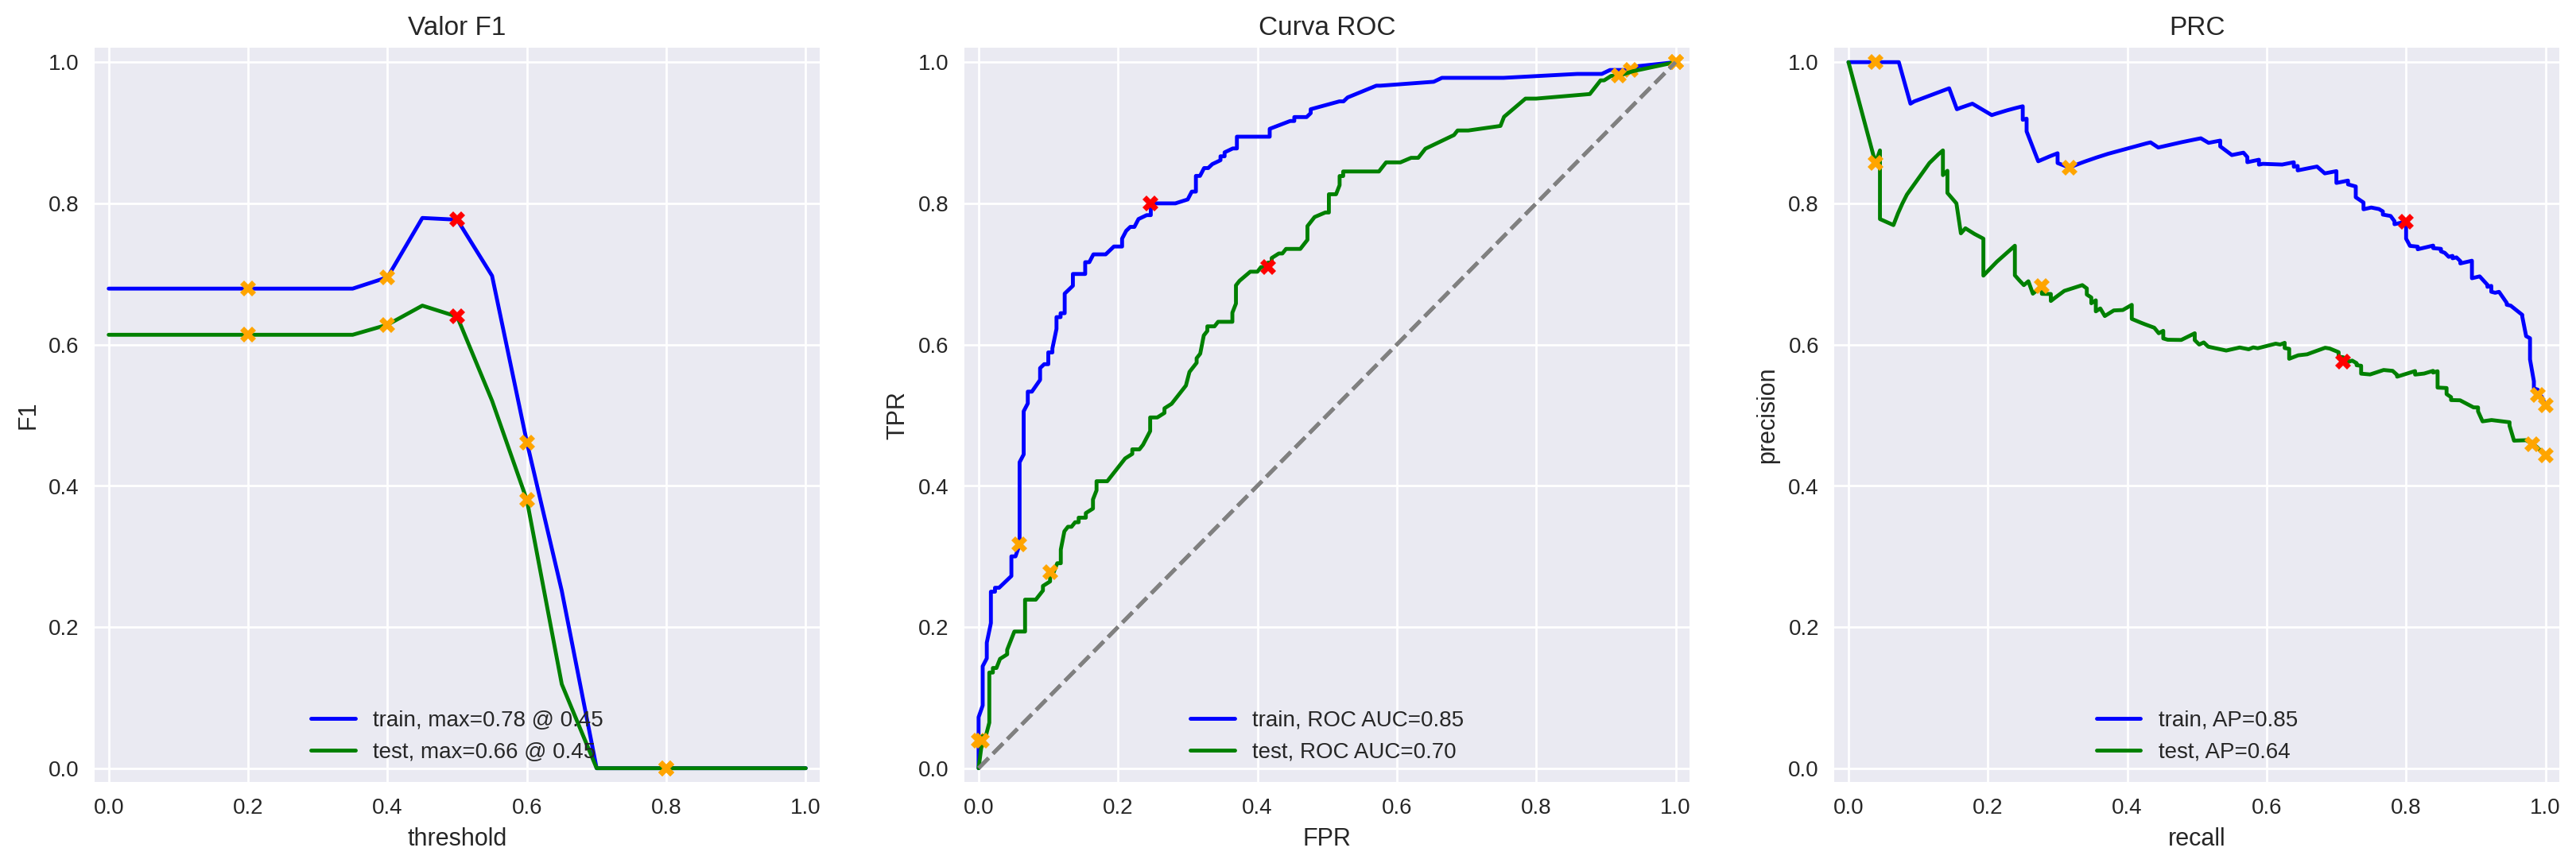

In [54]:
# Avaliar o modelo
evaluate_model(model_4_clf, train_features_BERT, train_target_BERT, test_features_BERT, test_target_BERT)

In [55]:
# Criar o modelo usando Random Forest

model_4_clf_ret = RandomForestClassifier(
    n_estimators=40,
    max_depth=2,
    min_samples_split=50,
    min_samples_leaf=15,
    random_state=42
)
# Treinando o modelo
model_4_clf_ret.fit(train_features_BERT, train_target_BERT)

RandomForestClassifier(max_depth=2, min_samples_leaf=15, min_samples_split=50,
                       n_estimators=40, random_state=42)

          train  test
Accuracy   0.85  0.68
F1         0.85  0.68
APS        0.94  0.69
ROC AUC    0.94  0.74


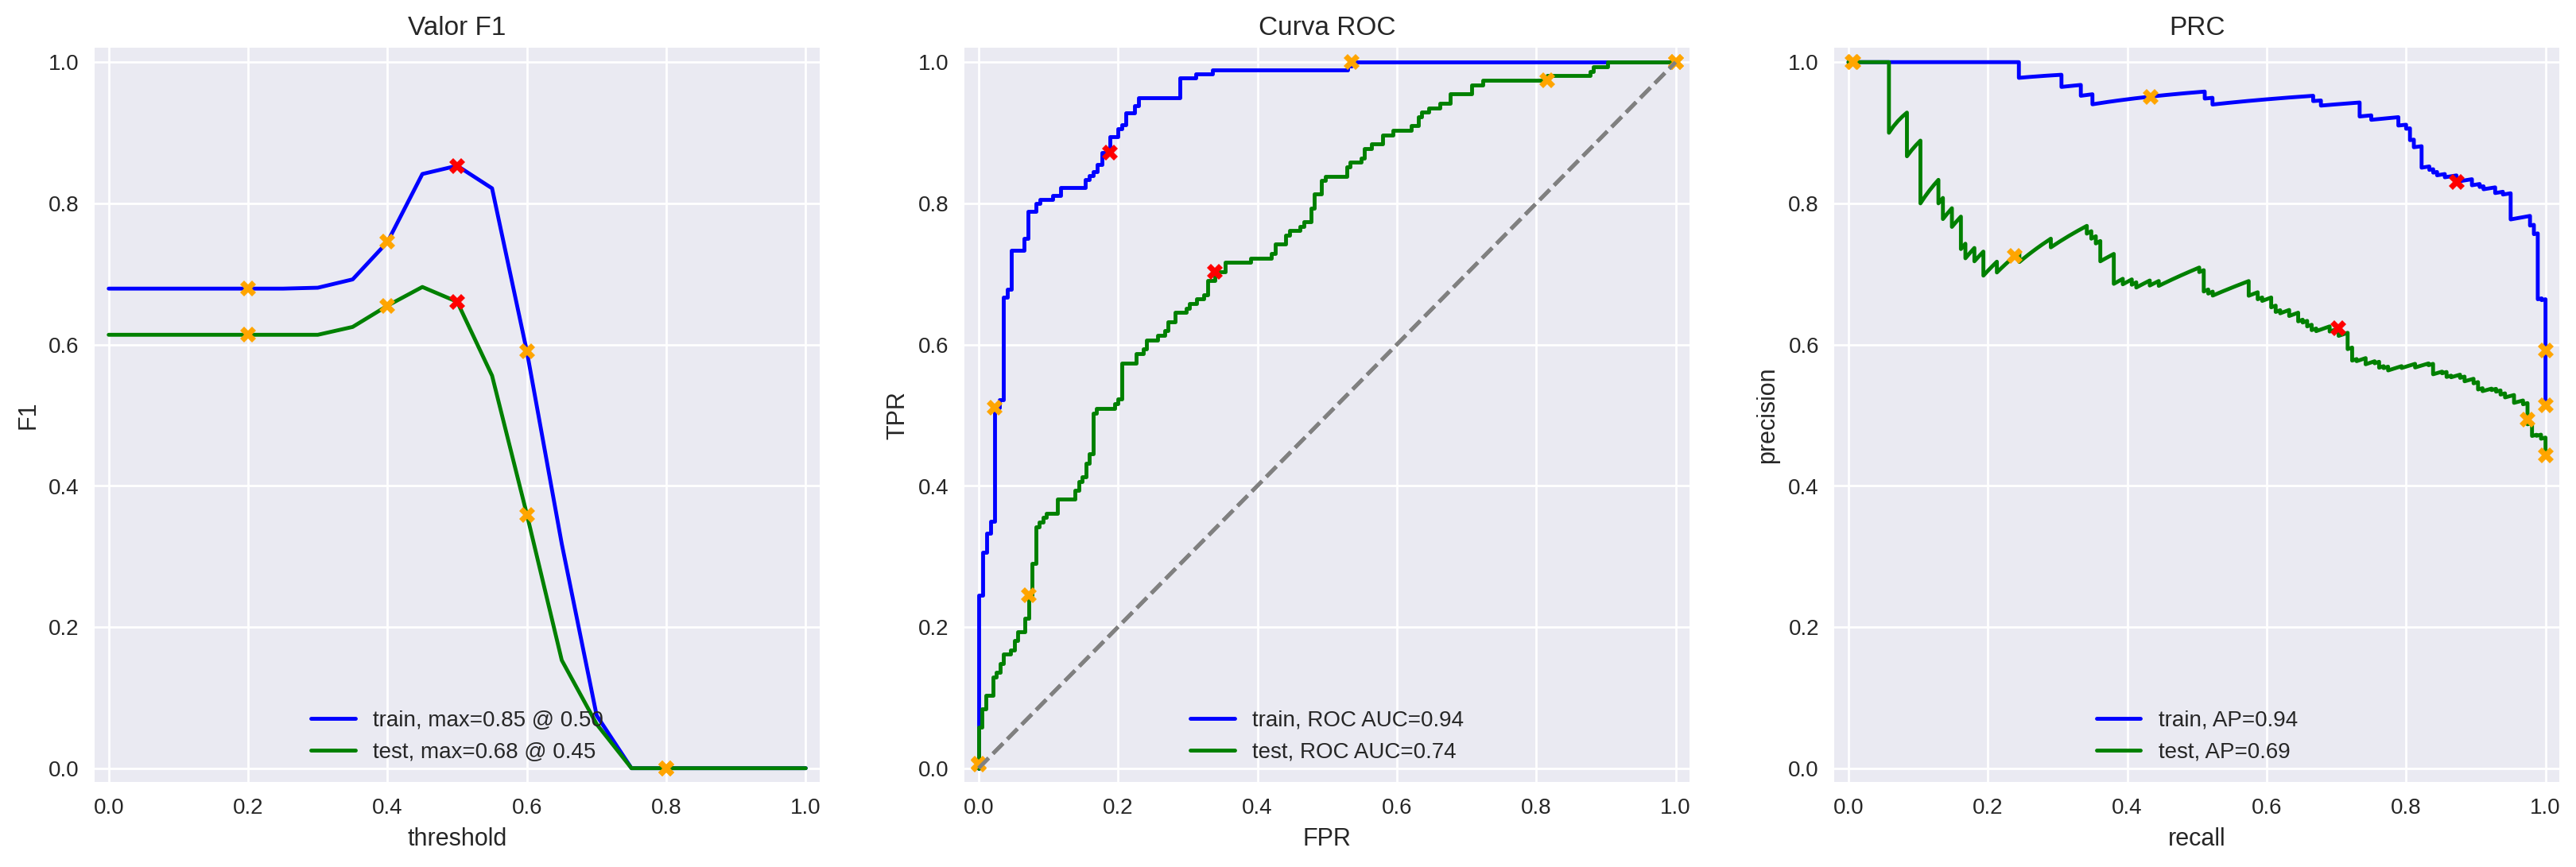

In [56]:
# Avaliar o modelo
evaluate_model(model_4_clf_ret, train_features_BERT, train_target_BERT, test_features_BERT, test_target_BERT)

In [57]:
# se você tiver as incorporações, é aconselhável salvá-las para tê-las prontas se
# np.savez_compressed('features_9.npz', train_features_9=train_features_9, test_features_9=test_features_9)

# e carregar...
# with np.load('features_9.npz') as data:
#     train_features_9 = data['train_features_9']
#     test_features_9 = data['test_features_9']

<div class="alert alert-block alert-warning">
Este trecho de salvamento/carregamento comentado ainda referencia os nomes de variáveis placeholder do template (`features_9`, etc.) em vez de suas variáveis reais (`train_features_BERT`, `test_features_BERT`). Atualizá-lo e descomentá-lo permitiria cachear seus embeddings BERT e economizar tempo significativo em execuções futuras, já que computá-los é a etapa mais cara neste notebook.
</div>

#### Analisando e entendo as células ácima
- Após a redução da amostra, já foi possível criar o modelo utilizando BERT
- Foi necessário jogar com os parámetros, porque atendendo o tamanho da amostra o treino do modelo tinha resultado 1.0 em tudo; um clássico overfit.
- Foi necessário jogar com alguns parámetros como o n_estimators (baixar), max_depth(baixar), aumentar o min_child_samples(no modelo usando LGBM) e adicionar o min_samples_split + min_samples_leaf no modelo usando Random Forest

## Minhas Resenhas

In [58]:
# sinta-se à vontade para remover completamente essas resenhas e experimentar seus modelos nas suas próprias resenhas, as abaixo são apenas exemplos

my_reviews = pd.DataFrame([
   "I simply didn't like it; it's not my kind of movie.",
    "Well, I got bored and fell asleep halfway through the movie.",
    "I was truly fascinated by the movie.",
    "The actors looked very old and uninterested, yet they still got paid to be in the movie. What a shameless rip-off.",
    "I didn't expect the new version to be so good! The writers really cared about the source material.",
    "The movie has its pros and cons, but I feel that overall it's a decent film. I can imagine myself going to watch it again.",
    "What a lousy attempt at comedy. Not a single joke lands, everyone acts in an annoying and loud way—even kids won't like this!",
    "Releasing it on Netflix was a bold move, and I really appreciate being able to watch episode after episode of this exciting and intelligent new drama."
], columns=['review'])

#my_reviews['review_norm'] = # <coloque aqui a mesma lógica de normalização do conjunto de dados principal>

#my_reviews

my_reviews['review_norm']=(
    my_reviews['review']
    .str.lower()
    .str.replace(r"[^a-z'\s]", '', regex=True) # Mantém apenas letras de a-z, apóstrofos e espaços
    .str.replace(r'\s+', ' ', regex=True) # Substitui multiplos espaços por apenas um
    .str.strip()                         # Remove espaços extras no início e no fim
)

<div class="alert alert-block alert-warning">
Seu próprio conjunto de revisão e lógica de normalização replicada funcionam corretamente. Dois pequenos ajustes: as linhas de comentário de espaço reservado restantes do template (`#my_reviews['review_norm'] = ...` e `#my_reviews`) podem ser removidas; e observe que essa normalização não remove tags HTML da mesma forma que seu pipeline principal agora faz — inofensivo aqui já que seus exemplos de revisões não contêm HTML, mas vale a pena manter em mente para consistência, por exemplo, reutilizando uma função de normalização compartilhada.
</div>

### Modelo 1

In [59]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_1.predict_proba(vetorizador.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.28:  i simply didn't like it it's not my kind of movie
0.13:  well i got bored and fell asleep halfway through the movie
0.70:  i was truly fascinated by the movie
0.18:  the actors looked very old and uninterested yet they still got paid to be in the movie what a shamel
0.27:  i didn't expect the new version to be so good the writers really cared about the source material
0.53:  the movie has its pros and cons but i feel that overall it's a decent film i can imagine myself goin
0.03:  what a lousy attempt at comedy not a single joke lands everyone acts in an annoying and loud wayeven
0.88:  releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


### Modelo 2

In [60]:
texts = my_reviews['review']

my_reviews_pred_prob = model_2.predict_proba(vetorizador_2.transform(texts.apply(lambda x: text_preprocessing_2(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.24:  I simply didn't like it; it's not my kind of movie.
0.07:  Well, I got bored and fell asleep halfway through the movie.
0.71:  I was truly fascinated by the movie.
0.05:  The actors looked very old and uninterested, yet they still got paid to be in the movie. What a sham
0.21:  I didn't expect the new version to be so good! The writers really cared about the source material.
0.45:  The movie has its pros and cons, but I feel that overall it's a decent film. I can imagine myself go
0.02:  What a lousy attempt at comedy. Not a single joke lands, everyone acts in an annoying and loud way—e
0.94:  Releasing it on Netflix was a bold move, and I really appreciate being able to watch episode after e


<div class="alert alert-block alert-success">
Detalhe importante feito corretamente aqui: você passa o texto *bruto* de `review` através de `text_preprocessing_2` antes de vetorizar, espelhando exatamente como `review_norm_2` foi construído para treinar este modelo. Manter o caminho de pré-processamento consistente entre treinamento e inferência é exatamente o que é necessário.
</div>

### Modelo 3

In [61]:
texts = my_reviews['review']

#tfidf_vectorizer_4 = tfidf_vectorizer_3
my_reviews_pred_prob = model_3.predict_proba(vetorizador_2.transform(texts.apply(lambda x: text_preprocessing_2(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.62:  I simply didn't like it; it's not my kind of movie.
0.45:  Well, I got bored and fell asleep halfway through the movie.
0.63:  I was truly fascinated by the movie.
0.52:  The actors looked very old and uninterested, yet they still got paid to be in the movie. What a sham
0.70:  I didn't expect the new version to be so good! The writers really cared about the source material.
0.57:  The movie has its pros and cons, but I feel that overall it's a decent film. I can imagine myself go
0.29:  What a lousy attempt at comedy. Not a single joke lands, everyone acts in an annoying and loud way—e
0.71:  Releasing it on Netflix was a bold move, and I really appreciate being able to watch episode after e


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


<div class="alert alert-block alert-warning">
Pequena limpeza: a linha comentada `#tfidf_vectorizer_4 = tfidf_vectorizer_3` referencia nomes de variáveis que não existem em lugar nenhum neste notebook e pode ser removida.
</div>

### Modelo 4

In [62]:
texts = my_reviews['review_norm']

my_reviews_features_4 = BERT_text_to_embeddings(texts, disable_progress_bar=True)

my_reviews_pred_prob = model_4_clf_ret.predict_proba(my_reviews_features_4)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.39:  i simply didn't like it it's not my kind of movie
0.38:  well i got bored and fell asleep halfway through the movie
0.51:  i was truly fascinated by the movie
0.54:  the actors looked very old and uninterested yet they still got paid to be in the movie what a shamel
0.43:  i didn't expect the new version to be so good the writers really cared about the source material
0.55:  the movie has its pros and cons but i feel that overall it's a decent film i can imagine myself goin
0.44:  what a lousy attempt at comedy not a single joke lands everyone acts in an annoying and loud wayeven
0.63:  releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


## Conclusões

##### Segue abaixo o resumo dos resultados dos vários modelos:
- Analisando os gráficos com os dados das duas classes, pdoe-se concluir que não existe nada de anormal ou de muito diferente entre as mesmas. O que quer dizer que estão muito equilibradas com 23715 resenhas negativas vs. 23616 positivas
- Model_1: Obteve F1_treino=0.92 e F1_teste=0.88, com valores de Accuracy_treino=0.92 e Accuracy_teste=0.88, e com valores de ROC AUC ácima dos 0.94 em ambos
- Model_2: Obteve F1_treino=0.91 e F1_teste=0.88, com valores de Accuracy_treino=0.91 e Accuracy_teste=0.87, e com valores de ROC AUC ácima dos 0.94 em ambos
- Model_3: F1_treino=0.87 e F1_teste=0.84, com valores de Accuracy_treino=0.87 e Accuracy_teste=0.84, e com valores de ROC AUC ácima dos 0.90 em ambos
- Model_4-LGBM: Obteve F1_treino=0.76 e F1_teste=0.72, com valores de Accuracy_treino=0.73 e Accuracy_teste=0.63, e com valores de ROC AUC bem abaixo dos 0.90 em ambos
- Model_4-RandomForest: Obteve F1_treino=0.86 e F1_teste=0.76, com valores de Accuracy_treino=0.85 e Accuracy_teste=0.69, e com valores de ROC AUC_trein=0.93 e para o teste=0.78 (uma diferença significativa)
- O Model_1 obteve melhor desempenho em paralelo com o Model_2, é importante frisar que não existe um campeão claro neste projecto analisando os números das métricas. Os modelos 1 & 2 obtiveram F1 muito próximos, e os valores da accuracy são: Model_1 accuracy_teste=0.87 e Model_2 accuracy_teste=0.88. Mas medindo o tempo de execução para desempatar o contexto, o Modelo 2 surge como campeão (Model 1 = 26 segundos de execução Vs Model 2 = 20 segundos de execução na altura da minha execução final). Os valores do tempo de execução variam a medida que vou correndo o notebook, mas contudo o Modelo 2 é o consistentemente mais rápido ao correr, o que me leva a indicar ele como o campeão dos modelos.
- O Modelo 4 (BERT), foi o modelo que utilizou a amostra de dados mais pequeno, por utilizar o BERT, que é computacionalmente muito pesado, por isso não se utilizou o dataset completo. Por não existir uma GPU o mesmo foi rodado na CPU, por isso teve um desempenho mais baixo. Em alguns momentos foi necessário ajustar bastante os parâmetros para se chegar aos valores actuais, porque houve overfit do modelo e teve-se que minimizar esta condição.

<div class="alert alert-block alert-warning">
Este é um resumo de métricas abrangente e a maioria dos números corresponde bem às tabelas impressas. Duas coisas ainda precisam de correção: (1) na sentença comparando Model_1 e Model_2 para o desempate, você escreve "Model_1 accuracy_teste=0.87 e Model_2 accuracy_teste=0.88," o que é o inverso de seus próprios marcadores logo acima (e da saída impressa atual), onde Model_1=0.88 e Model_2=0.87 — como essa comparação é o que o leva a escolher o tempo de execução como fator decisivo, por favor corrija-a contra suas próprias tabelas. (2) Os números do Model_4-RandomForest citados aqui (F1 0.86/0.76, Accuracy 0.85/0.69) não correspondem ao que a avaliação desta execução realmente imprimiu para esse modelo (Accuracy 0.83/0.69, F1 0.86/0.71) — muito provavelmente por causa do `.sample(350)` sem seed mencionado anteriormente. Assim que você adicionar um `random_state` ali, sincronize esses números com a nova saída.
</div>

- É importante ter em conta que, nem sempre o Modelo com a melhor performance é o mais aconselhável para ser utilizado. Por exemplo um Modelo com métricas excelenetes, grande performance, mas que leve muito tempo a ser executado pode ter um impacto negativo no negócio. Por ser muito lento, o mesmo leva mais tempo a ser executado e provávelmente consuma muitos recursos computacionais e por fezes torna o modelo ineficaz.
##### Recomendação
- Como recomendação, eu indico o Modelo 2 como o melhor para ser usado no Film Junky Union, por causa das suas métricas e o mesmo consome poucos recursos computacionais. Contudo, para este projecto não havendo grandes diferenças entre o Modelo 1 & 2, o Modelo 1 também pode ser usado para o Film em questão.

<div class="alert alert-block alert-success">
Bom julgamento prático aqui — reconhecer que o melhor modelo de desempenho no papel não é automaticamente a escolha certa para produção, e considerar o custo computacional e tempo de execução juntamente com as métricas brutas.
</div>

- O objectivo do projecto é de atingir um F1 >= 0.85 e houve pelo menos dois modelos que ultrapassaram este objecto de maneira clara (Meta atingida)
- Este projecto mostrou, que criar um sistema de IA, não apenas escolher o modelo mais moderno e forte do mercado, mas sim encontrar um equilíbrio perfeito entre a eficiência, capacidade de hardware e qualidade de previsão do modelo.
- Analisando o resultado os resultados dos vários modelos aplicados no my_reviews, as probabildades são as seguintes: Model_1(0.28, 0.13, 0.71, 0.18, 0.27, 0.53, 0.02, 0.88), Model_2(0.23, 0.07, 0.72, 0.05, 0.20, 0.44, 0.02, 0.94), Model_3(0.61, 0.44, 0.62, 0.53, 0.71, 0.58, 0.29, 0.72) e para o Model_4(0.41, 0.40, 0.47, 0.51, 0.35, 0.53, 0.34, 0.67)
- Os modelos 1, 2: São os nossos modelos de regressão logística e apresentam probabilidades altamente disperss e polarizadas, atingindo os extremos da escala com valores mínimos de 0.02 e máximos de 0.94
- O modelo 3: O nosso modelo de Gradient Boosting observa previsões consideravelmente mais conservadoras e agrupadas em torno do centro, variando de 0.29 à 0.72 sem a tingir certezas absolutas
- O modelo 4: O nosso modelo de rede neural BERT, alinhou-se ao comportamento do LightGBM, mantendo as probabilidades mais centradas e menos extremas
- A Regressão Logística calcula a probabilidade aplicando a função sigmoide à combinação linear dos recursos. Ao trabalhar com representações textuais baseadas em TF-IDF, o modelo lida com uma matriz de altíssima dimensão (milhares de palavras separadas).
- Modelos baseados em conjuntos de árvores de decisão geram suas probabilidades finais através da média dos caminhos percorridos em dezenas ou centenas de árvores independentes. Diferente de um modelo linear, o LightGBM avalia os recursos de forma sequencial e condicional (divisões por nós). Como o algoritmo impõe regras estritas de regularização (como número mínimo de amostras por folha para evitar overfitting), os nós terminais raramente contêm uma pureza absoluta de 100%. Ao tirar a média dessas folhas combinadas, o resultado final é suavizado e puxado de volta para a região central (em torno de 0,5), impedindo o modelo de pontuar com certeza máxima
-  BERT se comporta de forma semelhante ao LightGBM devido à natureza de seus embeddings. Em vez de olhar para palavras isoladas e pontuais (como o TF-IDF), o BERT comprime o significado do texto em um vetor denso e contínuo de 768 dimensões que captura o contexto, ironias e nuances
- Concluindo podemos dizer que enquantos uns lidam com maior cautela matemática saudável que reflete a real ambiguidade presente na linguagem humana, outros lidam com acumular contagens de palavras como é o caso da Regressão Logística. Por isso diz-se conlui-se que maior dispersão não significa necessariamente melhor calibração.
- Para a escolha do modelo campeão em produção, a métrica de decisão deve ser o F1-Score: se os modelos com probabilidades centradas (LightGBM/BERT) mantiveram ou superaram a assertividade dos modelos lineares, eles provam ser arquiteturas muito mais robustas e menos propensas a falhar com convicção falsa.

<div class="alert alert-block alert-warning">
Bom, comparação qualitativa precisa da dispersão de probabilidades entre os modelos de regressão logística (extrema/polarizada) e o modelo de gradient boosting (mais centralizado). Duas coisas que valem a pena corrigir: (1) as probabilidades de Model_4 listadas aqui (0.41, 0.40, 0.47, 0.51, 0.35, 0.53, 0.34, 0.67) não correspondem ao que a célula de predição BERT+RandomForest realmente imprimiu nesta execução (0.34, 0.42, 0.47, 0.34, 0.40, 0.57, 0.34, 0.68) — novamente, provavelmente devido à amostra não seeded a montante; re-copie os valores assim que isso for corrigido. (2) A explicação de que BERT centraliza suas probabilidades porque seus embeddings "capturam contexto, ironia, nuance" é um pouco vaga — uma explicação mais concreta apontaria para a amostra de treinamento muito pequena e não seeded de 350 reviews combinada com o classificador raso e fortemente regularizado (`max_depth=2`, `min_samples_leaf` alto) situado no topo dos embeddings, o que empurra as predições em direção a 0.5 independentemente de quão ricos os embeddings são.
</div>

# Checklist

- [x]  O caderno foi aberto
- [x]  Os dados de texto são carregados e pré-processados para vetorização
- [x]  Os dados de texto são transformados em vetores
- [x]  Os modelos são treinados e testados
- [x]  O limiar da métrica foi atingido
- [x]  Todas as células de código estão organizadas na ordem de sua execução
- [x]  Todas as células de código podem ser executadas sem erros
- [x]  Há conclusões

<div class="alert alert-block alert-success">
Esta lista de verificação reflete com precisão o estado atual do seu notebook — com a correção `review_norm_2` implementada, o notebook agora genuinamente executa de cima para baixo sem erros, os dados de texto são carregados/pré-processados/vetorizados, múltiplos modelos são treinados e testados, o limiar de F1 é alcançado por vários deles, e as conclusões estão presentes.
</div>